# MERFISH Uterine Cancer Modular Clean Splat Notebook


In [1]:
from pathlib import Path
import sys

import hashlib
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import re
import random
import torch
from scipy.ndimage import distance_transform_edt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import AmplitudeSplatField, DataConfig, SplatConfig, TrainingConfig, build_cell_only_targets, capture_initial_splat_state, composition_cosine_loss, compute_splat_weights, create_amplitude_splat_optimizer, evaluate_cell_readout, evaluate_count_model, farthest_point_sample_indices, log_total_count_loss, mae_count_loss, make_split_indices, predict_cell_log_rates, sample_numpy_grid, sample_tissue_support, summarize_activity_slices, summarize_error_slices, usage_statistics, GeneProfileAutoencoder, evaluate_profile_autoencoder, train_profile_autoencoder
from spatsplat.baselines import CountMLP, FourierFeatureMLP, KNNCountRegressor, MeanProfileBaseline
from paper.data_loaders.merfish_uterine_cancer import load_merfish_uterine_cancer_dataset


In [2]:
dataset_name = 'merfish-uterinecancer-p2-RACstain'
include_blank_probes = False
load_transcripts = False  # The raw transcript table is very large; keep this off by default.

data_cfg = DataConfig(mask_grid_size=256, cell_mask_min_radius=1.0)
splat_cfg = SplatConfig(num_splats=768, latent_dim=32, hidden_dim=128, init_log_scale=-4.5, kernel_sharpness=1.0)
init_log_amplitude = 7.0
train_cfg = TrainingConfig(
    baseline_epochs=100,
    splat_epochs=200,
    baseline_batch_size=4096,
    bin_batch_size=2048,
    cell_batch_size=4096,
    off_tissue_batch_size=4096,
    bin_loss_weight=0.05,
    cell_loss_weight=1.0,
    off_tissue_weight=0.001,
    center_support_weight=0.01,
    #splat_means_lr=5e-3,
    splat_means_lr=2.5e-3,
    splat_log_scales_lr=1e-3,
    splat_rotation_lr=1e-3,
    splat_opacity_lr=1e-3,
    #splat_latents_lr=1e-3,
    splat_latents_lr=5e-4,
    splat_log_theta_lr=1e-3,
    #splat_decoder_lr=1e-3,
    splat_decoder_lr=5e-4,
    splat_total_count_head_lr=1e-3,
)

notebook_seed = 1023
split_seed = notebook_seed
ae_seed = notebook_seed + 1
seed_init_seed = notebook_seed + 2
baseline_mean_seed = notebook_seed + 3
baseline_mlp_mae_seed = notebook_seed + 4
baseline_mlp_bio_seed = notebook_seed + 5
baseline_fourier_mae_seed = notebook_seed + 6
baseline_fourier_bio_seed = notebook_seed + 7
baseline_budget_knn_seed = notebook_seed + 8
random_model_seed = notebook_seed + 9
random_train_seed = notebook_seed + 10
ae_train_seed = notebook_seed + 11
ae_frozen_train_seed = notebook_seed + 12
ae_unfrozen_train_seed = notebook_seed + 13
layout_seed = notebook_seed + 14
overlap_seed = notebook_seed + 15
comparison_gene_of_interest = 'EPCAM'

reuse_ae_checkpoint = True
force_retrain_ae = False
reuse_coarse_checkpoints = True
force_retrain_coarse = False
checkpoint_run_name = '768_batch_half_learning_rates'  # Optional manual tag like 'ks075_bs4096_lrhalf'.


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def maybe_clear_cuda():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

set_seed(notebook_seed)
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

loaded = load_merfish_uterine_cancer_dataset(
    dataset_name=dataset_name,
    include_blank_probes=include_blank_probes,
    load_transcripts=load_transcripts,
)
dataset = build_cell_only_targets(loaded, data_cfg)

device = loaded.device
trans_df = loaded.trans_df
adata = loaded.adata
gene_list = loaded.gene_list
gene_to_id = loaded.gene_to_id
num_genes = loaded.num_genes

bin_features = dataset.bin_features
bin_targets = dataset.bin_targets
cell_features = dataset.cell_features
cell_spans = dataset.cell_spans
cell_targets = dataset.cell_targets
off_tissue_points = dataset.off_tissue_points
tissue_mask_tensor = dataset.tissue_mask_tensor
mask_grid_size = dataset.mask_grid_size

print(f"Device: {device}")
print(f"Dataset: {dataset_name}")
print(f"Loaded transcripts for overlays: {len(trans_df):,}")
print(f"Genes: {num_genes:,}")
print(f"Cells after join: {adata.n_obs:,}")
print(f"Cells with transcript counts: {len(cell_features):,}")
print(f"Initial log amplitude: {init_log_amplitude}")
print(f"Kernel sharpness: {splat_cfg.kernel_sharpness}")
print('Memory note: this dataset is large; consider saving intermediate results and calling maybe_clear_cuda() between heavy sections if GPU memory becomes tight.')

def _slugify_figure_name(text: str) -> str:
    text = (text or '').strip().lower()
    text = re.sub(r'[^a-z0-9]+', '_', text)
    text = re.sub(r'_+', '_', text).strip('_')
    return text or 'figure'

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'merfish_uterine_cancer_modular_clean_v2'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths

def compute_overlap_usage_for_active_splats(model, features, means_np, scales_xy_np, rotation_np, active_idx, fallback_usage, batch_size: int = 512):
    overlap_sum = np.zeros(len(fallback_usage), dtype=np.float64)
    overlap_count = np.zeros(len(fallback_usage), dtype=np.int64)
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            batch = features[start:start + batch_size]
            batch_xy = batch.detach().cpu().numpy()
            batch_weights = compute_splat_weights(model, batch).detach().cpu().numpy()
            for splat_idx in active_idx:
                dx = batch_xy[:, 0] - means_np[splat_idx, 0]
                dy = batch_xy[:, 1] - means_np[splat_idx, 1]
                theta = -float(rotation_np[splat_idx])
                c, s = np.cos(theta), np.sin(theta)
                x_rot = c * dx - s * dy
                y_rot = s * dx + c * dy
                sx = max(float(scales_xy_np[splat_idx, 0]), 1e-8)
                sy = max(float(scales_xy_np[splat_idx, 1]), 1e-8)
                inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
                if inside_mask.any():
                    overlap_sum[splat_idx] += float(batch_weights[inside_mask, splat_idx].sum())
                    overlap_count[splat_idx] += int(inside_mask.sum())
    if was_training:
        model.train()
    overlap_usage = fallback_usage.astype(np.float64).copy()
    valid = overlap_count > 0
    overlap_usage[valid] = overlap_sum[valid] / overlap_count[valid]
    return overlap_usage, overlap_count



Device: cuda
Dataset: merfish-uterinecancer-p2-RACstain
Loaded transcripts for overlays: 0
Genes: 500
Cells after join: 741,749
Cells with transcript counts: 741,749
Initial log amplitude: 7.0
Kernel sharpness: 1.0
Memory note: this dataset is large; consider saving intermediate results and calling maybe_clear_cuda() between heavy sections if GPU memory becomes tight.


This uterine-cancer dataset is substantially larger than the earlier notebooks. Keep outputs stripped, save intermediate results when useful, and call `maybe_clear_cuda()` between the AE, baselines, and coarse training sections if GPU memory becomes tight.


## Tissue View

Inspect the raw spatial-unit layout before adding any modeling code.


In [ ]:
cell_points_np = cell_features.detach().cpu().numpy()
cell_total_counts_np = cell_targets.sum(dim=1).detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)

axes[0].scatter(cell_points_np[sample_idx, 0], cell_points_np[sample_idx, 1], s=2, alpha=0.2, color="black")
axes[0].set_title("Measurements")

vmax = np.quantile(cell_total_counts_np, 0.99) if len(cell_total_counts_np) else 1.0
sc = axes[1].scatter(
    cell_points_np[sample_idx, 0],
    cell_points_np[sample_idx, 1],
    c=cell_total_counts_np[sample_idx],
    s=8,
    cmap="magma",
    alpha=0.8,
    vmin=0.0,
    vmax=vmax,
)
axes[1].set_title("Measurements Colored By Total Counts")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='measurements_overview')
plt.show()

print(f"Cells shown: {sample_n:,} / {len(cell_points_np):,}")
print(f"Total count summary: mean={format_scalar(cell_total_counts_np.mean())} | median={format_scalar(np.median(cell_total_counts_np))} | max={format_scalar(cell_total_counts_np.max())}")


## Tissue Mask Diagnostics

Check the support mask directly against the observed spatial-unit positions.


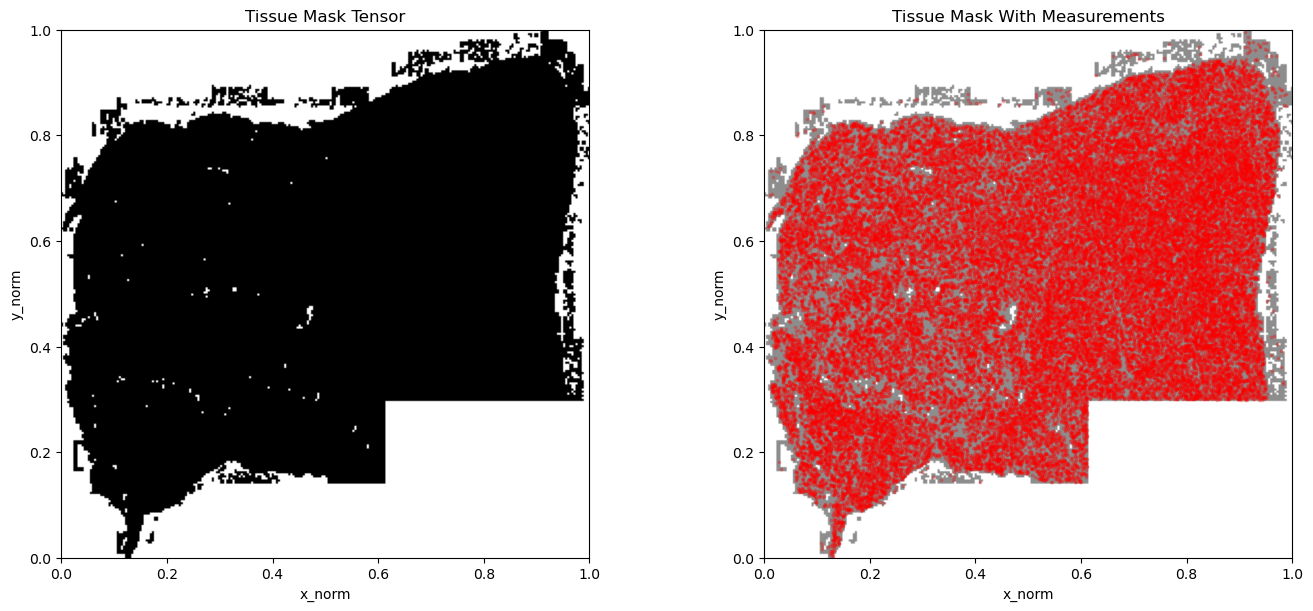

Tissue mask coverage summary
{'mask_shape': [256, 256], 'mask_mean': 0.651, 'mask_binary_fraction_gt_0.05': 0.651, 'sampled_spatial_units': 50000}


In [4]:
mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy()
mask_binary = mask_np > 0.05
cell_points_np = cell_features.detach().cpu().numpy()

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)
sample_xy = cell_points_np[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

axes[0].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r")
axes[0].set_title("Tissue Mask Tensor")

axes[1].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.45)
axes[1].scatter(sample_xy[:, 0], sample_xy[:, 1], s=3, alpha=0.25, color="red")
axes[1].set_title("Tissue Mask With Measurements")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix='tissue_mask')
plt.show()

print("Tissue mask coverage summary")
print(format_for_display({
    "mask_shape": tuple(mask_np.shape),
    "mask_mean": float(mask_np.mean()),
    "mask_binary_fraction_gt_0.05": float(mask_binary.mean()),
    "sampled_spatial_units": int(sample_n),
}))


## Normalized Profile Autoencoder

Train an encoder/decoder on normalized gene-expression profiles so the latent space can later be used to initialize splat biology programs.


In [ ]:
set_seed(ae_seed)
cell_train_idx, cell_val_idx, cell_test_idx = make_split_indices(len(cell_features), seed=split_seed, device=device)

cell_total_counts = cell_targets.sum(dim=1, keepdim=True).clamp_min(1.0)
cell_profiles = cell_targets.float() / cell_total_counts

ae_epochs = 300
ae_batch_size = 256
ae_lr = 1e-3

ae_checkpoint_dir = PROJECT_ROOT / 'checkpoints' / 'merfish_uterine_cancer_modular_clean'
ae_checkpoint_dir.mkdir(parents=True, exist_ok=True)

def config_hash(config: dict) -> str:
    config_json = json.dumps(config, sort_keys=True, separators=(',', ':'))
    return hashlib.sha1(config_json.encode('utf-8')).hexdigest()[:10]


def checkpoint_suffix(prefix: str, config: dict) -> str:
    cfg_hash = config_hash(config)
    if checkpoint_run_name:
        run_name = re.sub(r'[^a-zA-Z0-9_-]+', '_', str(checkpoint_run_name)).strip('_')
        return f"{prefix}_{run_name}_{cfg_hash}"
    return f"{prefix}_{cfg_hash}"


ae_checkpoint_config = {
    'dataset_name': dataset_name,
    'latent_dim': int(splat_cfg.latent_dim),
    'hidden_dim': int(splat_cfg.hidden_dim),
    'num_genes': int(num_genes),
    'ae_epochs': int(ae_epochs),
    'ae_batch_size': int(ae_batch_size),
    'ae_lr': float(ae_lr),
    'ae_seed': int(ae_seed),
    'split_seed': int(split_seed),
}
ae_checkpoint_suffix = checkpoint_suffix('profile_autoencoder', ae_checkpoint_config)
ae_checkpoint_path = ae_checkpoint_dir / f'{ae_checkpoint_suffix}.pt'
ae_config_json_path = ae_checkpoint_dir / f'{ae_checkpoint_suffix}.json'
legacy_ae_checkpoint_path = ae_checkpoint_dir / f'profile_autoencoder_latent{splat_cfg.latent_dim}_hidden{splat_cfg.hidden_dim}_epochs{ae_epochs}.pt'


def save_profile_autoencoder_checkpoint(model, optimizer, history, test_metrics):
    payload = {
        'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
        'optimizer_state_dict': optimizer.state_dict(),
        'history': history,
        'test_metrics': test_metrics,
        'config': ae_checkpoint_config,
    }
    torch.save(payload, ae_checkpoint_path)
    ae_config_json_path.write_text(json.dumps(ae_checkpoint_config, indent=2, sort_keys=True))


def resolve_ae_checkpoint_path() -> Path | None:
    if ae_checkpoint_path.exists():
        return ae_checkpoint_path
    if legacy_ae_checkpoint_path.exists():
        return legacy_ae_checkpoint_path
    return None


def load_profile_autoencoder_checkpoint(model, optimizer=None):
    checkpoint_path = resolve_ae_checkpoint_path()
    if checkpoint_path is None:
        raise FileNotFoundError('No AE checkpoint found for current configuration')
    payload = torch.load(checkpoint_path, map_location='cpu')
    model.load_state_dict(payload['model_state_dict'])
    if optimizer is not None and 'optimizer_state_dict' in payload:
        optimizer.load_state_dict(payload['optimizer_state_dict'])
    payload['resolved_checkpoint_path'] = str(checkpoint_path)
    return payload


set_seed(ae_seed)
profile_autoencoder = GeneProfileAutoencoder(
    num_genes=num_genes,
    hidden_dim=splat_cfg.hidden_dim,
    latent_dim=splat_cfg.latent_dim,
).to(device)
profile_autoencoder_opt = torch.optim.Adam(profile_autoencoder.parameters(), lr=ae_lr)

ae_history = None
ae_test_metrics = None

print(format_for_display({
    'train_cells': int(len(cell_train_idx)),
    'val_cells': int(len(cell_val_idx)),
    'test_cells': int(len(cell_test_idx)),
    'latent_dim': int(splat_cfg.latent_dim),
    'hidden_dim': int(splat_cfg.hidden_dim),
    'ae_checkpoint_path': str(ae_checkpoint_path),
    'ae_config_json_path': str(ae_config_json_path),
    'reuse_ae_checkpoint': bool(reuse_ae_checkpoint),
    'force_retrain_ae': bool(force_retrain_ae),
}))


## Autoencoder Training

Optimize the encoder/decoder only on normalized profiles. Total-count magnitude stays outside this path.


In [ ]:
if reuse_ae_checkpoint and resolve_ae_checkpoint_path() is not None and not force_retrain_ae:
    checkpoint_payload = load_profile_autoencoder_checkpoint(profile_autoencoder, optimizer=profile_autoencoder_opt)
    profile_autoencoder = profile_autoencoder.to(device)
    ae_history = checkpoint_payload.get('history', {'train_loss': [], 'val_loss': [], 'val_mae': [], 'val_cosine': []})
    ae_test_metrics = checkpoint_payload.get(
        'test_metrics',
        evaluate_profile_autoencoder(profile_autoencoder, cell_profiles, cell_test_idx, batch_size=ae_batch_size),
    )
    print(f"Loaded AE checkpoint from {checkpoint_payload['resolved_checkpoint_path']}")
else:
    def _record_ae_epoch(epoch, train_loss, val_metrics):
        print(f"AE epoch {epoch} | train_loss={format_scalar(train_loss)} | val={format_for_display(val_metrics)}")

    ae_history = train_profile_autoencoder(
        profile_autoencoder,
        cell_profiles,
        cell_train_idx,
        cell_val_idx,
        epochs=ae_epochs,
        batch_size=ae_batch_size,
        optimizer=profile_autoencoder_opt,
        max_grad_norm=5.0,
        on_epoch_end=_record_ae_epoch,
    )
    ae_test_metrics = evaluate_profile_autoencoder(profile_autoencoder, cell_profiles, cell_test_idx, batch_size=ae_batch_size)
    save_profile_autoencoder_checkpoint(profile_autoencoder, profile_autoencoder_opt, ae_history, ae_test_metrics)
    print(f'Saved AE checkpoint to {ae_checkpoint_path}')
    print(f'Saved AE config to {ae_config_json_path}')

print('Normalized-profile autoencoder test')
print(format_for_display(ae_test_metrics))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(ae_history['train_loss'], label='train')
axes[0].plot(ae_history['val_loss'], label='val')
axes[0].set_title('AE Reconstruction Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy')
axes[0].legend()

axes[1].plot(ae_history['val_mae'])
axes[1].set_title('AE Validation Profile MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean absolute error')

axes[2].plot(ae_history['val_cosine'])
axes[2].set_title('AE Validation Cosine')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Mean cosine similarity')

export_figure_axes(fig, fallback_prefix='ae_training')
plt.show()


## Autoencoder Diagnostics

Check whether reconstructed normalized profiles preserve overall composition and marker structure well enough to support latent initialization.


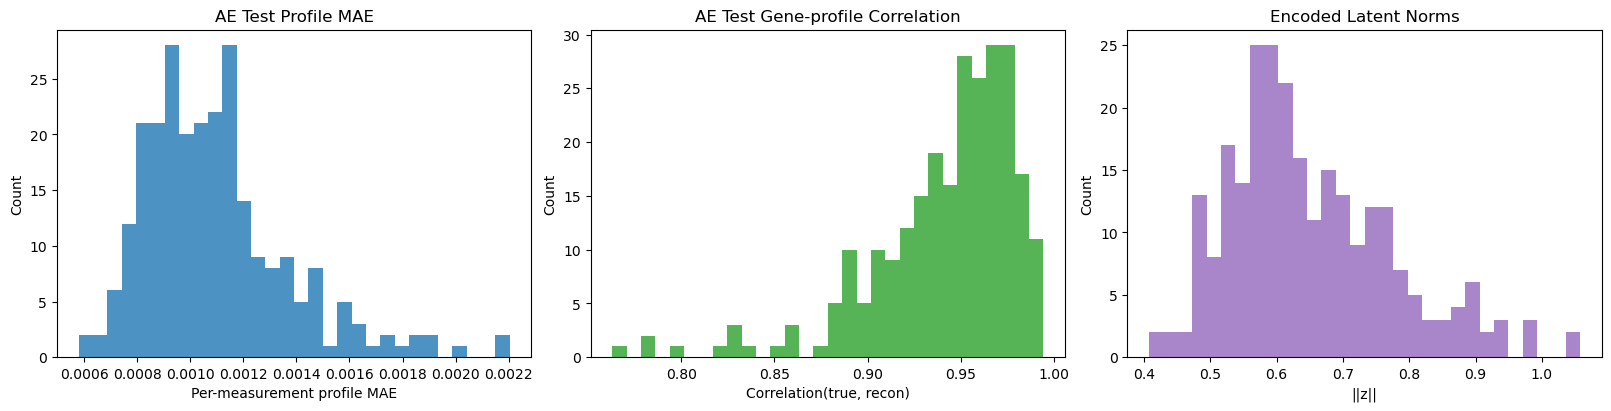

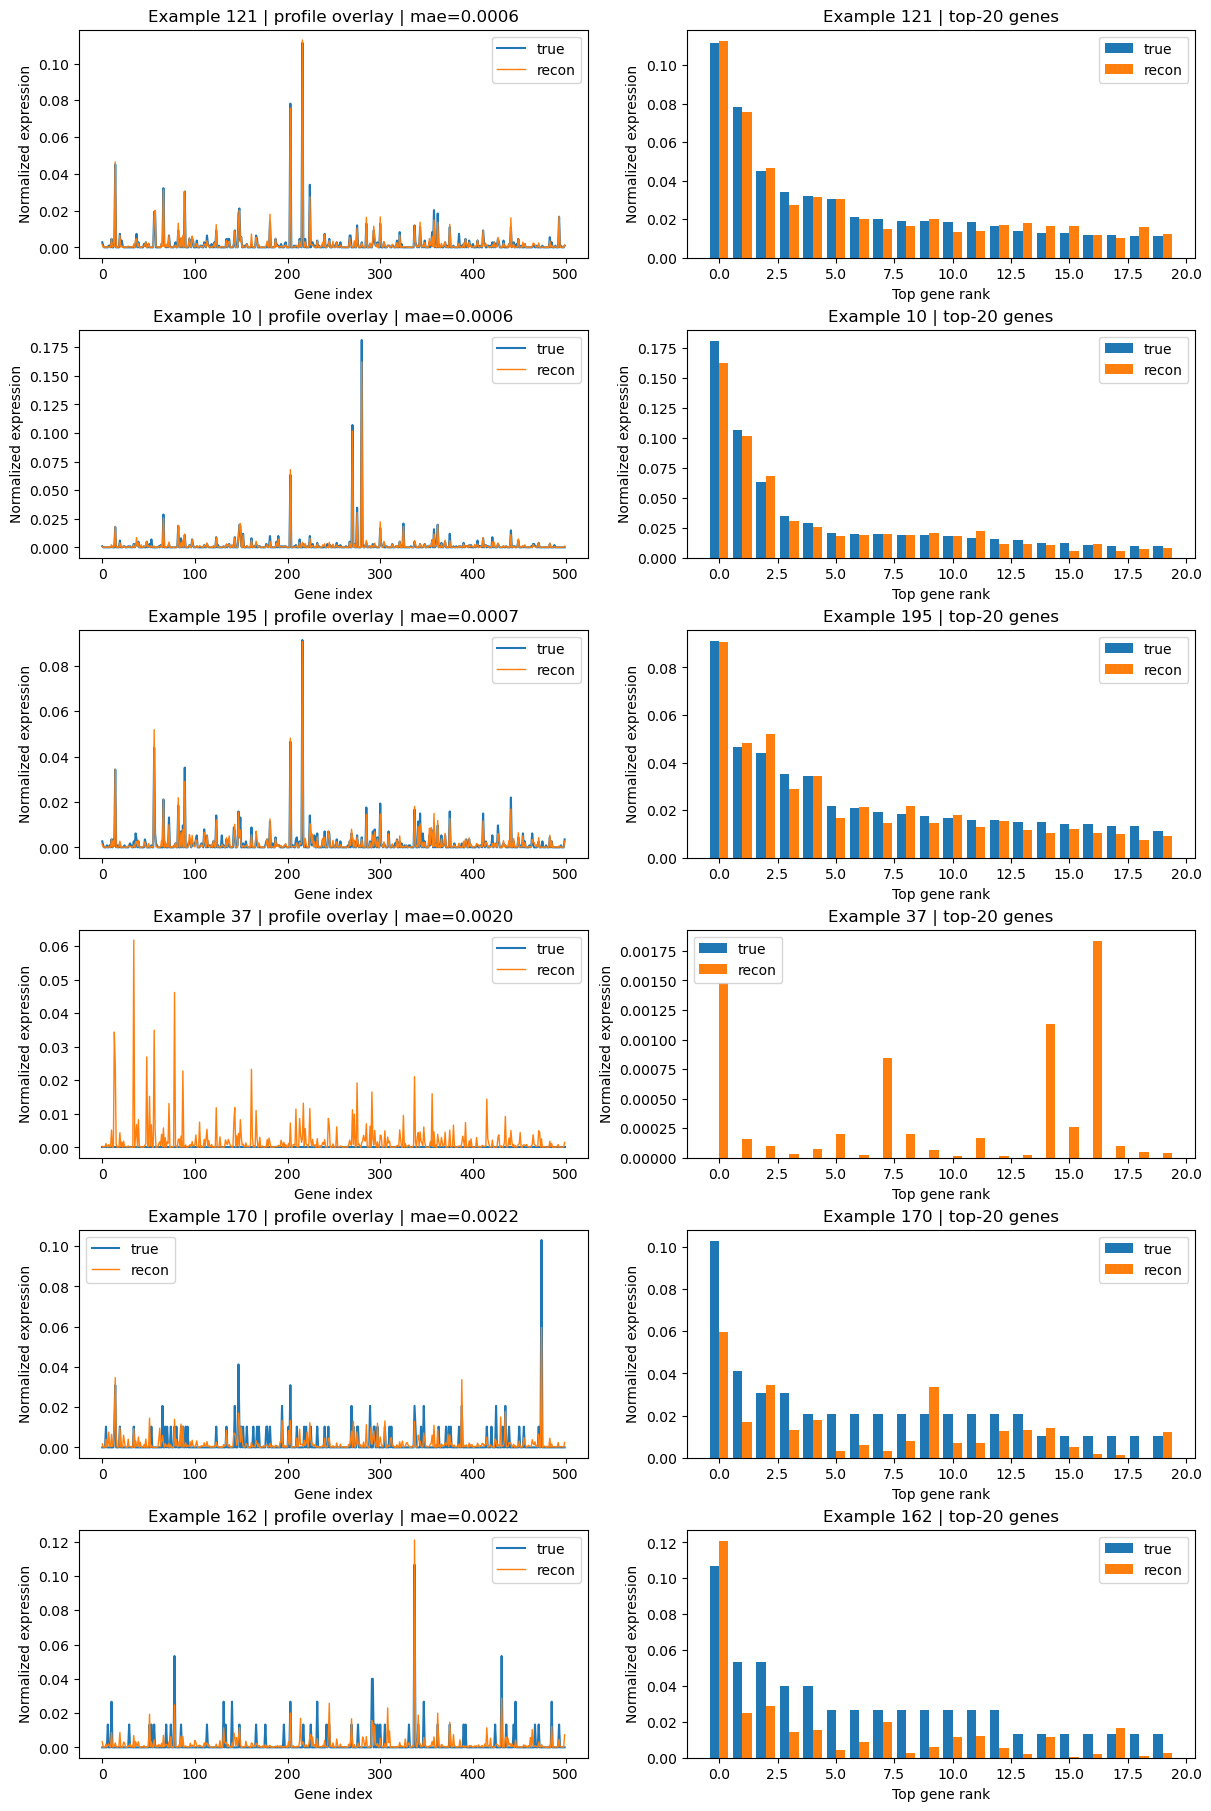

{'diag_cells': 256, 'diag_mae_mean': 0.001, 'diag_mae_median': 0.001, 'diag_corr_mean': 0.941, 'diag_corr_median': 0.951}
AE zero/low-count diagnostic summary
{'diag_cells': 256, 'zero_count_cells': 0, 'count_le_1': 1, 'count_le_5': 1, 'count_le_10': 1, 'count_le_25': 1, 'mean_total_count': 392.207, 'median_total_count': 359.0}
Filtered AE diagnostic summary by minimum total count
{'total_count>=1': {'n': 256, 'mae_mean': 0.001, 'mae_median': 0.001, 'corr_mean': 0.941, 'corr_median': 0.951, 'mean_nonzero_fraction': 0.244}, 'total_count>=5': {'n': 255, 'mae_mean': 0.001, 'mae_median': 0.001, 'corr_mean': 0.941, 'corr_median': 0.951, 'mean_nonzero_fraction': 0.245}, 'total_count>=10': {'n': 255, 'mae_mean': 0.001, 'mae_median': 0.001, 'corr_mean': 0.941, 'corr_median': 0.951, 'mean_nonzero_fraction': 0.245}, 'total_count>=25': {'n': 255, 'mae_mean': 0.001, 'mae_median': 0.001, 'corr_mean': 0.941, 'corr_median': 0.951, 'mean_nonzero_fraction': 0.245}}
Worst AE test examples by MAE
[{'loca

In [7]:
set_seed(seed_init_seed)
with torch.no_grad():
    diag_idx = cell_test_idx[:min(len(cell_test_idx), 256)]
    diag_profiles = cell_profiles[diag_idx]
    diag_latents, _, diag_recon_profiles = profile_autoencoder(diag_profiles)

diag_mae = (diag_recon_profiles - diag_profiles).abs().mean(dim=1).detach().cpu().numpy()
diag_true_np = diag_profiles.detach().cpu().numpy()
diag_recon_np = diag_recon_profiles.detach().cpu().numpy()
diag_latent_np = diag_latents.detach().cpu().numpy()
diag_corr = [np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan for t, r in zip(diag_true_np, diag_recon_np)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(diag_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('AE Test Profile MAE')
axes[0].set_xlabel('Per-measurement profile MAE')
axes[0].set_ylabel('Count')

axes[1].hist([x for x in diag_corr if np.isfinite(x)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('AE Test Gene-profile Correlation')
axes[1].set_xlabel('Correlation(true, recon)')
axes[1].set_ylabel('Count')

latent_norms = np.linalg.norm(diag_latent_np, axis=1)
axes[2].hist(latent_norms, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Encoded Latent Norms')
axes[2].set_xlabel('||z||')
axes[2].set_ylabel('Count')

export_figure_axes(fig, fallback_prefix='ae_test_summary')
plt.show()

diag_idx_np = diag_idx.detach().cpu().numpy()
diag_corr_np = np.asarray(diag_corr, dtype=np.float64)
worst_mae_order = np.argsort(diag_mae)[::-1]
finite_corr_mask = np.isfinite(diag_corr_np)
worst_corr_order = np.argsort(diag_corr_np[finite_corr_mask]) if finite_corr_mask.any() else np.array([], dtype=np.int64)
finite_corr_local_idx = np.flatnonzero(finite_corr_mask)
worst_k = min(5, len(diag_mae))
worst_mae_examples = [
    {
        'local_diag_index': int(local_idx),
        'original_cell_index': int(diag_idx_np[local_idx]),
        'mae': float(diag_mae[local_idx]),
        'corr': float(diag_corr_np[local_idx]) if np.isfinite(diag_corr_np[local_idx]) else float('nan'),
    }
    for local_idx in worst_mae_order[:worst_k]
]
worst_corr_examples = [
    {
        'local_diag_index': int(finite_corr_local_idx[pos]),
        'original_cell_index': int(diag_idx_np[finite_corr_local_idx[pos]]),
        'mae': float(diag_mae[finite_corr_local_idx[pos]]),
        'corr': float(diag_corr_np[finite_corr_local_idx[pos]]),
    }
    for pos in worst_corr_order[:worst_k]
]

example_idx = np.argsort(diag_mae)[:3].tolist() + np.argsort(diag_mae)[-3:].tolist()
example_idx = list(dict.fromkeys(example_idx))
fig, axes = plt.subplots(len(example_idx), 2, figsize=(12, 3 * len(example_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_idx):
    axes[row, 0].plot(diag_true_np[local_idx], label='true', linewidth=1.5)
    axes[row, 0].plot(diag_recon_np[local_idx], label='recon', linewidth=1.0)
    axes[row, 0].set_title(f'Example {local_idx} | profile overlay | mae={diag_mae[local_idx]:.4f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(diag_true_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, diag_true_np[local_idx, gene_order], width=0.4, label='true')
    axes[row, 1].bar(x + 0.2, diag_recon_np[local_idx, gene_order], width=0.4, label='recon')
    axes[row, 1].set_title(f'Example {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

export_figure_axes(fig, fallback_prefix='ae_examples')
plt.show()

diag_total_counts = cell_total_counts[diag_idx].squeeze(-1).detach().cpu().numpy()
diag_nonzero_fraction = (diag_true_np > 0).mean(axis=1)

def summarize_count_filter(total_counts_np, mae_np, corr_np, min_total_count: float):
    mask = total_counts_np >= float(min_total_count)
    return {
        'n': int(mask.sum()),
        'mae_mean': float(np.mean(mae_np[mask])) if mask.any() else float('nan'),
        'mae_median': float(np.median(mae_np[mask])) if mask.any() else float('nan'),
        'corr_mean': float(np.nanmean(corr_np[mask])) if mask.any() else float('nan'),
        'corr_median': float(np.nanmedian(corr_np[mask])) if mask.any() else float('nan'),
        'mean_nonzero_fraction': float(np.mean(diag_nonzero_fraction[mask])) if mask.any() else float('nan'),
    }

zero_count_summary = {
    'diag_cells': int(len(diag_total_counts)),
    'zero_count_cells': int(np.sum(diag_total_counts == 0)),
    'count_le_1': int(np.sum(diag_total_counts <= 1)),
    'count_le_5': int(np.sum(diag_total_counts <= 5)),
    'count_le_10': int(np.sum(diag_total_counts <= 10)),
    'count_le_25': int(np.sum(diag_total_counts <= 25)),
    'mean_total_count': float(np.mean(diag_total_counts)),
    'median_total_count': float(np.median(diag_total_counts)),
}
filtered_ae_diag_summary = {
    'total_count>=1': summarize_count_filter(diag_total_counts, diag_mae, diag_corr_np, 1),
    'total_count>=5': summarize_count_filter(diag_total_counts, diag_mae, diag_corr_np, 5),
    'total_count>=10': summarize_count_filter(diag_total_counts, diag_mae, diag_corr_np, 10),
    'total_count>=25': summarize_count_filter(diag_total_counts, diag_mae, diag_corr_np, 25),
}

print(format_for_display({
    'diag_cells': int(len(diag_idx)),
    'diag_mae_mean': float(np.mean(diag_mae)),
    'diag_mae_median': float(np.median(diag_mae)),
    'diag_corr_mean': float(np.nanmean(diag_corr)),
    'diag_corr_median': float(np.nanmedian(diag_corr)),
}))
print('AE zero/low-count diagnostic summary')
print(format_for_display(zero_count_summary))
print('Filtered AE diagnostic summary by minimum total count')
print(format_for_display(filtered_ae_diag_summary))
print('Worst AE test examples by MAE')
print(format_for_display(worst_mae_examples))
print('Worst AE test examples by correlation')
print(format_for_display(worst_corr_examples))


## Encoder-Initialized Splats

Use the trained encoder to initialize splat latents from local neighborhoods around initial splat centers.


In [8]:
init_neighbor_k = 16

with torch.no_grad():
    seed_idx = farthest_point_sample_indices(cell_features, splat_cfg.num_splats)
    seed_xy = cell_features[seed_idx]
    pairwise_dist = torch.cdist(seed_xy, cell_features)
    neighbor_k = min(init_neighbor_k, cell_features.shape[0])
    neighbor_dist, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

    neighbor_profiles = cell_profiles[neighbor_idx]
    neighbor_totals = cell_total_counts[neighbor_idx]
    avg_profiles = neighbor_profiles.mean(dim=1)
    avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
    avg_totals = neighbor_totals.mean(dim=1)
    encoded_seed_latents = profile_autoencoder.encoder(avg_profiles)

encoder_initialized_splat_model = AmplitudeSplatField(
    num_splats=splat_cfg.num_splats,
    latent_dim=splat_cfg.latent_dim,
    hidden_dim=splat_cfg.hidden_dim,
    num_genes=num_genes,
    init_log_scale=splat_cfg.init_log_scale,
    kernel_sharpness=splat_cfg.kernel_sharpness,
    init_log_amplitude=init_log_amplitude,
).to(device)

with torch.no_grad():
    encoder_initialized_splat_model.means.copy_(seed_xy)
    encoder_initialized_splat_model.latents.copy_(encoded_seed_latents)
    encoder_initialized_splat_model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
    encoder_initialized_splat_model.log_scales.fill_(splat_cfg.init_log_scale)
    encoder_initialized_splat_model.rotation.zero_()
    encoder_initialized_splat_model.opacity_logits.zero_()
    encoder_initialized_splat_model.decoder.load_state_dict(profile_autoencoder.decoder.state_dict())

print(format_for_display({
    'num_splats': int(splat_cfg.num_splats),
    'neighbor_k': int(neighbor_k),
    'seed_profile_shape': tuple(avg_profiles.shape),
    'seed_latent_shape': tuple(encoded_seed_latents.shape),
    'mean_neighbor_total_count': float(avg_totals.mean().item()),
    'median_neighbor_total_count': float(avg_totals.median().item()),
}))


{'num_splats': 768, 'neighbor_k': 16, 'seed_profile_shape': [768, 500], 'seed_latent_shape': [768, 32], 'mean_neighbor_total_count': 375.608, 'median_neighbor_total_count': 396.438}


## Encoder Initialization Diagnostics

Inspect the seed locations and compare neighborhood-averaged profiles against the decoder output from the initialized latents.


In [ ]:
with torch.no_grad():
    seed_gene_logits, _ = encoder_initialized_splat_model.decoder(encoded_seed_latents)
    decoded_seed_profiles = torch.softmax(seed_gene_logits, dim=1)

seed_xy_np = seed_xy.detach().cpu().numpy()
avg_profiles_np = avg_profiles.detach().cpu().numpy()
decoded_seed_profiles_np = decoded_seed_profiles.detach().cpu().numpy()
avg_totals_np = avg_totals.squeeze(-1).detach().cpu().numpy()
neighbor_radius_np = neighbor_dist[:, -1].detach().cpu().numpy()
seed_mae = np.mean(np.abs(decoded_seed_profiles_np - avg_profiles_np), axis=1)
seed_corr = np.array([
    np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan
    for t, r in zip(avg_profiles_np, decoded_seed_profiles_np)
], dtype=np.float64)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=5, alpha=0.12, color='black')
sc0 = axes[0].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=avg_totals_np, s=30, cmap='magma', alpha=0.9)
axes[0].set_title('Initial Splat Centers Colored By Local Total Count')
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=neighbor_radius_np, s=30, cmap='viridis', alpha=0.9)
axes[1].set_title('Initial Splat Centers Colored By Neighborhood Radius')
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

sc2 = axes[2].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=seed_corr, s=30, cmap='coolwarm', alpha=0.9, vmin=0.0, vmax=1.0)
axes[2].set_title('Initial Splat Centers Colored By AE Seed Correlation')
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='seed_centers')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(seed_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('Seed Profile MAE')
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Count')

axes[1].hist(seed_corr[np.isfinite(seed_corr)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('Seed Profile Correlation')
axes[1].set_xlabel('Correlation')
axes[1].set_ylabel('Count')

axes[2].hist(avg_totals_np, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Neighborhood Mean Total Count')
axes[2].set_xlabel('Mean total count')
axes[2].set_ylabel('Count')

export_figure_axes(fig, fallback_prefix='seed_summary')
plt.show()

best_seed_idx = np.argsort(seed_mae)[:3].tolist()
worst_seed_idx = np.argsort(seed_mae)[-3:].tolist()
example_seed_idx = list(dict.fromkeys(best_seed_idx + worst_seed_idx))
fig, axes = plt.subplots(len(example_seed_idx), 2, figsize=(12, 3 * len(example_seed_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_seed_idx):
    axes[row, 0].plot(avg_profiles_np[local_idx], label='neighbor avg', linewidth=1.5)
    axes[row, 0].plot(decoded_seed_profiles_np[local_idx], label='decoded seed', linewidth=1.0)
    axes[row, 0].set_title(f'Seed {local_idx} | mae={seed_mae[local_idx]:.4f} | corr={seed_corr[local_idx]:.3f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(avg_profiles_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, avg_profiles_np[local_idx, gene_order], width=0.4, label='neighbor avg')
    axes[row, 1].bar(x + 0.2, decoded_seed_profiles_np[local_idx, gene_order], width=0.4, label='decoded seed')
    axes[row, 1].set_title(f'Seed {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

export_figure_axes(fig, fallback_prefix='seed_examples')
plt.show()

print(format_for_display({
    'seed_mae_mean': float(np.mean(seed_mae)),
    'seed_mae_median': float(np.median(seed_mae)),
    'seed_corr_mean': float(np.nanmean(seed_corr)),
    'seed_corr_median': float(np.nanmedian(seed_corr)),
    'neighbor_radius_mean': float(np.mean(neighbor_radius_np)),
    'neighbor_radius_median': float(np.median(neighbor_radius_np)),
}))


## Baselines

Run the same baseline models used in the older notebook on the canonical train/val/test split before coarse splat training.


In [ ]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.3
mae_refine_weight = 1.0
mae_refine_fraction = 0.25

train_cell_features = cell_features[cell_train_idx]
train_cell_targets = cell_targets[cell_train_idx]
baseline_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_cfg.baseline_epochs)))

def train_mae_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            loss = reconstruction_loss_fn(model(cell_features[idx]), cell_targets[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

def train_bio_objective_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        mae_refine_active = epoch >= baseline_mae_refine_start_epoch
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            pred_log_rate = model(cell_features[idx])
            pred_counts = torch.exp(pred_log_rate)
            cell_loss = mae_count_loss(pred_log_rate, cell_targets[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(pred_counts, cell_targets[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, cell_targets[idx])
            loss = (
                mae_refine_weight * cell_loss
                + composition_loss_weight * composition_loss
                + total_count_loss_weight * total_count_loss
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

set_seed(baseline_mean_seed)
mean_cell_model = MeanProfileBaseline(train_cell_targets).to(device)
mean_cell_val = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
mean_cell_test = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Mean baseline')
print(format_for_display(mean_cell_val))
print(format_for_display(mean_cell_test))

set_seed(baseline_mlp_mae_seed)
cell_mlp_mae = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_mae_opt = torch.optim.Adam(cell_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_mlp_mae, cell_mlp_mae_opt)
cell_mlp_mae_val = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_mae_test = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP-MAE')
print(format_for_display(cell_mlp_mae_val))
print(format_for_display(cell_mlp_mae_test))

set_seed(baseline_mlp_bio_seed)
cell_mlp = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_opt = torch.optim.Adam(cell_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_mlp, cell_mlp_opt)
cell_mlp_val = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_test = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP (Bio Objective)')
print(format_for_display(cell_mlp_val))
print(format_for_display(cell_mlp_test))

set_seed(baseline_fourier_mae_seed)
cell_fourier_mlp_mae = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_mlp_mae_opt = torch.optim.Adam(cell_fourier_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_fourier_mlp_mae, cell_fourier_mlp_mae_opt)
cell_fourier_mlp_mae_val = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_mlp_mae_test = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP-MAE')
print(format_for_display(cell_fourier_mlp_mae_val))
print(format_for_display(cell_fourier_mlp_mae_test))

set_seed(baseline_fourier_bio_seed)
cell_fourier_mlp = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_opt = torch.optim.Adam(cell_fourier_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_fourier_mlp, cell_fourier_opt)
cell_fourier_val = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_test = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP (Bio Objective)')
print(format_for_display(cell_fourier_val))
print(format_for_display(cell_fourier_test))

cell_knn = KNNCountRegressor(train_cell_features, train_cell_targets, k=64).to(device)
cell_knn_val = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_knn_test = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('KNN')
print(format_for_display(cell_knn_val))
print(format_for_display(cell_knn_test))

set_seed(baseline_budget_knn_seed)
budget_knn_budget = min(splat_cfg.num_splats, len(cell_train_idx))
budget_knn_candidate_limit = None
if len(cell_train_idx) > 100000:
    budget_knn_candidate_limit = min(len(cell_train_idx), max(4 * budget_knn_budget, 50000))
budget_knn_local_idx = farthest_point_sample_indices(
    train_cell_features,
    budget_knn_budget,
    candidate_limit=budget_knn_candidate_limit,
    random_state=baseline_budget_knn_seed,
)
cell_budget_knn = KNNCountRegressor(
    train_cell_features[budget_knn_local_idx],
    train_cell_targets[budget_knn_local_idx],
    k=64,
).to(device)
cell_budget_knn_val = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_budget_knn_test = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('Budget-matched KNN')
print(format_for_display({
    'prototype_cells': int(len(budget_knn_local_idx)),
    'candidate_pool': int(budget_knn_candidate_limit or len(cell_train_idx)),
}))
print(format_for_display(cell_budget_knn_val))
print(format_for_display(cell_budget_knn_test))

baseline_summary = {
    'Mean baseline': {'val': mean_cell_val, 'test': mean_cell_test},
    'MLP-MAE': {'val': cell_mlp_mae_val, 'test': cell_mlp_mae_test},
    'MLP (Bio Objective)': {'val': cell_mlp_val, 'test': cell_mlp_test},
    'Fourier MLP-MAE': {'val': cell_fourier_mlp_mae_val, 'test': cell_fourier_mlp_mae_test},
    'Fourier MLP (Bio Objective)': {'val': cell_fourier_val, 'test': cell_fourier_test},
    'KNN': {'val': cell_knn_val, 'test': cell_knn_test},
    'Budget-matched KNN': {'val': cell_budget_knn_val, 'test': cell_budget_knn_test},
}
print('Baseline summary')
print(format_for_display(baseline_summary))

for model_name in ['mean_cell_model', 'cell_mlp_mae', 'cell_mlp', 'cell_fourier_mlp_mae', 'cell_fourier_mlp']:
    globals()[model_name] = globals()[model_name].cpu()
del cell_mlp_mae_opt
del cell_mlp_opt
del cell_fourier_mlp_mae_opt
del cell_fourier_opt
if torch.cuda.is_available():
    torch.cuda.empty_cache()


## Splat Training Setup

Train the coarse splat field twice with the same objective and schedule: once from random initialization and once from AE-neighbor initialization.


In [11]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.2
mae_refine_weight = 1.0
mae_refine_fraction = 0.25
freeze_geometry_during_mae_refine = True
coarse_log_every = 10

def build_random_splat_model():
    return AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=num_genes,
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)

def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned


coarse_checkpoint_dir = PROJECT_ROOT / 'checkpoints' / 'merfish_uterine_cancer_modular_clean'
coarse_checkpoint_dir.mkdir(parents=True, exist_ok=True)

def coarse_result_slug(label: str) -> str:
    slug = label.lower()
    slug = re.sub(r'[^a-z0-9]+', '_', slug).strip('_')
    return slug


coarse_checkpoint_config = {
    'dataset_name': dataset_name,
    'num_splats': int(splat_cfg.num_splats),
    'latent_dim': int(splat_cfg.latent_dim),
    'hidden_dim': int(splat_cfg.hidden_dim),
    'init_log_scale': float(splat_cfg.init_log_scale),
    'kernel_sharpness': float(splat_cfg.kernel_sharpness),
    'init_log_amplitude': float(init_log_amplitude),
    'splat_epochs': int(train_cfg.splat_epochs),
    'bin_batch_size': int(train_cfg.bin_batch_size),
    'cell_batch_size': int(train_cfg.cell_batch_size),
    'off_tissue_batch_size': int(train_cfg.off_tissue_batch_size),
    'bin_loss_weight': float(train_cfg.bin_loss_weight),
    'cell_loss_weight': float(train_cfg.cell_loss_weight),
    'off_tissue_weight': float(train_cfg.off_tissue_weight),
    'center_support_weight': float(train_cfg.center_support_weight),
    'splat_means_lr': float(train_cfg.splat_means_lr),
    'splat_log_scales_lr': float(train_cfg.splat_log_scales_lr),
    'splat_rotation_lr': float(train_cfg.splat_rotation_lr),
    'splat_opacity_lr': float(train_cfg.splat_opacity_lr),
    'splat_latents_lr': float(train_cfg.splat_latents_lr),
    'splat_log_theta_lr': float(train_cfg.splat_log_theta_lr),
    'splat_decoder_lr': float(train_cfg.splat_decoder_lr),
    'splat_total_count_head_lr': float(train_cfg.splat_total_count_head_lr),
    'composition_loss_weight': float(composition_loss_weight),
    'total_count_loss_weight': float(total_count_loss_weight),
    'mae_refine_weight': float(mae_refine_weight),
    'mae_refine_fraction': float(mae_refine_fraction),
    'freeze_geometry_during_mae_refine': bool(freeze_geometry_during_mae_refine),
}
coarse_checkpoint_suffix = checkpoint_suffix('coarse', coarse_checkpoint_config)
coarse_config_json_path = coarse_checkpoint_dir / f'{coarse_checkpoint_suffix}.json'


def coarse_checkpoint_path(label: str) -> Path:
    return coarse_checkpoint_dir / f"{coarse_result_slug(label)}__{coarse_checkpoint_suffix}.pt"


def legacy_coarse_checkpoint_path(label: str) -> Path:
    return coarse_checkpoint_dir / f"{coarse_result_slug(label)}.pt"


def resolve_coarse_checkpoint_path(label: str) -> Path | None:
    new_path = coarse_checkpoint_path(label)
    if new_path.exists():
        return new_path
    legacy_path = legacy_coarse_checkpoint_path(label)
    if legacy_path.exists():
        return legacy_path
    return None


def _result_model_config(model):
    return {
        'num_splats': int(model.num_splats),
        'latent_dim': int(model.latent_dim),
        'hidden_dim': int(model.hidden_dim),
        'num_genes': int(model.num_genes),
        'init_log_scale': float(model.init_log_scale),
        'kernel_sharpness': float(model.kernel_sharpness),
        'init_log_amplitude': float(model.log_amplitudes.detach().mean().item()),
    }


def save_and_offload_coarse_result(result):
    model = result['model']
    checkpoint_path = coarse_checkpoint_path(result['label'])
    payload = {
        'label': result['label'],
        'model_config': _result_model_config(model),
        'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
        'history': result['history'],
        'train_metrics': result['train_metrics'],
        'val_metrics': result['val_metrics'],
        'test_metrics': result['test_metrics'],
        'initial_state': result['initial_state'],
        'config': coarse_checkpoint_config,
    }
    torch.save(payload, checkpoint_path)
    coarse_config_json_path.write_text(json.dumps(coarse_checkpoint_config, indent=2, sort_keys=True))
    result['checkpoint_path'] = str(checkpoint_path)
    result['model'] = model.cpu()
    maybe_clear_cuda()
    return result


def load_coarse_result(label: str):
    checkpoint_path = resolve_coarse_checkpoint_path(label)
    if checkpoint_path is None:
        raise FileNotFoundError(f'No coarse checkpoint found for {label}')
    payload = torch.load(checkpoint_path, map_location='cpu')
    model = AmplitudeSplatField(**payload['model_config'])
    model.load_state_dict(payload['model_state_dict'])
    model.eval()
    return {
        'label': payload['label'],
        'model': model,
        'initial_state': payload['initial_state'],
        'history': payload['history'],
        'train_metrics': payload['train_metrics'],
        'val_metrics': payload['val_metrics'],
        'test_metrics': payload['test_metrics'],
        'checkpoint_path': str(checkpoint_path),
    }


def get_or_train_coarse_result(initial_model, label: str, seed: int, freeze_decoder: bool = False, freeze_geometry_during_mae: bool = True, num_epochs=None):
    checkpoint_path = resolve_coarse_checkpoint_path(label)
    if reuse_coarse_checkpoints and checkpoint_path is not None and not force_retrain_coarse:
        print(f'Loaded coarse checkpoint for {label} from {checkpoint_path}')
        return load_coarse_result(label)
    checkpoint_path = coarse_checkpoint_path(label)
    result = train_coarse_splat_model(
        initial_model,
        label=label,
        seed=seed,
        freeze_decoder=freeze_decoder,
        freeze_geometry_during_mae=freeze_geometry_during_mae,
        num_epochs=num_epochs,
    )
    result = save_and_offload_coarse_result(result)
    print(f'Saved coarse checkpoint for {label} to {checkpoint_path}')
    print(f'Saved coarse config to {coarse_config_json_path}')
    return result


def restore_result_model(result):
    model = result.get('model')
    if model is None:
        payload = torch.load(result['checkpoint_path'], map_location='cpu')
        model = AmplitudeSplatField(**payload['model_config'])
        model.load_state_dict(payload['model_state_dict'])
        result['model'] = model
    result['model'] = result['model'].to(device)
    result['model'].eval()
    return result['model']


def offload_result_model(result):
    if result.get('model') is not None:
        result['model'] = result['model'].cpu()
    maybe_clear_cuda()


usage_eval_batch_size = 2048
neighbor_eval_splat_batch_size = 64


def batched_mean_splat_usage(model, queries: torch.Tensor, batch_size: int = usage_eval_batch_size):
    total_weight = torch.zeros(model.num_splats, device=model.means.device)
    total_queries = 0
    with torch.no_grad():
        for start in range(0, len(queries), batch_size):
            batch_queries = queries[start:start + batch_size]
            batch_weights = compute_splat_weights(model, batch_queries)
            total_weight += batch_weights.sum(dim=0)
            total_queries += int(batch_weights.shape[0])
    if total_queries == 0:
        return total_weight
    return total_weight / float(total_queries)


def batched_local_total_statistics(model, features: torch.Tensor, total_counts: torch.Tensor, neighbor_k: int, splat_batch_size: int = neighbor_eval_splat_batch_size):
    local_mean_chunks = []
    local_median_chunks = []
    with torch.no_grad():
        for start in range(0, model.num_splats, splat_batch_size):
            stop = min(start + splat_batch_size, model.num_splats)
            pairwise_dist = torch.cdist(model.means[start:stop], features)
            _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)
            local_totals = total_counts[neighbor_idx].squeeze(-1)
            local_mean_chunks.append(local_totals.mean(dim=1))
            local_median_chunks.append(local_totals.median(dim=1).values)
            del pairwise_dist, neighbor_idx, local_totals
            maybe_clear_cuda()
    return torch.cat(local_mean_chunks, dim=0), torch.cat(local_median_chunks, dim=0)

def train_coarse_splat_model(initial_model, label: str, seed: int, freeze_decoder: bool = False, freeze_geometry_during_mae: bool = True, num_epochs = None):
    set_seed(seed)
    splat_model = clone_splat_model(initial_model)
    if freeze_decoder:
        for param in splat_model.decoder.parameters():
            param.requires_grad_(False)
    initial_state = capture_initial_splat_state(splat_model)
    splat_opt = create_amplitude_splat_optimizer(
        splat_model,
        means_lr=train_cfg.splat_means_lr,
        log_scales_lr=train_cfg.splat_log_scales_lr,
        rotation_lr=train_cfg.splat_rotation_lr,
        opacity_lr=train_cfg.splat_opacity_lr,
        latents_lr=train_cfg.splat_latents_lr,
        log_theta_lr=train_cfg.splat_log_theta_lr,
        decoder_lr=train_cfg.splat_decoder_lr,
        amplitude_lr=train_cfg.splat_total_count_head_lr,
    )
    train_epochs = int(train_cfg.splat_epochs if num_epochs is None else num_epochs)
    coarse_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_epochs)))
    history = {
        'train_joint_loss': [],
        'train_composition_loss': [],
        'train_total_count_loss': [],
        'train_cell_loss': [],
        'val_loss': [],
        'val_mae': [],
        'val_phase': [],
    }
    print(f"{label} | coarse loss weights: composition={format_scalar(composition_loss_weight)}, total={format_scalar(total_count_loss_weight)}, mae_refine={format_scalar(mae_refine_weight)}, off_tissue={format_scalar(train_cfg.off_tissue_weight)}, center_support={format_scalar(train_cfg.center_support_weight)}, freeze_decoder={freeze_decoder}, freeze_geometry_during_mae={freeze_geometry_during_mae}")

    for epoch in range(train_epochs):
        splat_model.train()
        mae_refine_active = epoch >= coarse_mae_refine_start_epoch
        geometry_lr_scale = 0.0 if (mae_refine_active and freeze_geometry_during_mae) else 1.0
        splat_opt.param_groups[0]['lr'] = train_cfg.splat_means_lr * geometry_lr_scale
        splat_opt.param_groups[1]['lr'] = train_cfg.splat_log_scales_lr * geometry_lr_scale
        splat_opt.param_groups[2]['lr'] = train_cfg.splat_rotation_lr * geometry_lr_scale
        splat_opt.param_groups[3]['lr'] = train_cfg.splat_opacity_lr * geometry_lr_scale
        splat_opt.param_groups[4]['lr'] = train_cfg.splat_latents_lr
        splat_opt.param_groups[5]['lr'] = train_cfg.splat_log_theta_lr
        splat_opt.param_groups[6]['lr'] = 0.0 if freeze_decoder else train_cfg.splat_decoder_lr
        splat_opt.param_groups[7]['lr'] = train_cfg.splat_total_count_head_lr
        cell_perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device)
        batch_size = min(train_cfg.cell_batch_size, 1024)
        off_batch_size = min(train_cfg.off_tissue_batch_size, 1024)
        num_steps = max(1, (len(cell_perm) + batch_size - 1) // batch_size)
        running = {
            'joint_loss': 0.0,
            'cell_loss': 0.0,
            'composition_loss': 0.0,
            'total_count_loss': 0.0,
            'off_tissue_loss': 0.0,
            'center_support_loss': 0.0,
        }

        for step in range(num_steps):
            cell_start = (step * batch_size) % len(cell_perm)
            off_start = (step * off_batch_size) % len(off_perm)
            cell_idx = cell_perm[cell_start:cell_start + batch_size]
            off_idx = off_perm[off_start:off_start + off_batch_size]
            if len(cell_idx) == 0:
                cell_idx = cell_perm[:batch_size]
            if len(off_idx) == 0:
                off_idx = off_perm[:off_batch_size]

            pred_cell_log_rate = predict_cell_log_rates(
                splat_model,
                cell_features[cell_idx],
                cell_spans[cell_idx],
                batch_size=batch_size,
            )
            off_tissue_intensity = splat_model.total_intensity(off_tissue_points[off_idx])
            center_support = sample_tissue_support(splat_model.means, tissue_mask_tensor)

            cell_loss = mae_count_loss(pred_cell_log_rate, cell_targets[cell_idx]) if mae_refine_active else pred_cell_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_cell_log_rate), cell_targets[cell_idx])
            total_count_loss = log_total_count_loss(pred_cell_log_rate, cell_targets[cell_idx])
            off_tissue_loss = off_tissue_intensity.mean()
            center_support_loss = (1.0 - center_support).mean()
            loss = mae_refine_weight * cell_loss + composition_loss_weight * composition_loss + total_count_loss_weight * total_count_loss + train_cfg.off_tissue_weight * off_tissue_loss + train_cfg.center_support_weight * center_support_loss

            splat_opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(splat_model.parameters(), max_norm=5.0)
            splat_opt.step()

            with torch.no_grad():
                splat_model.means.clamp_(0.0, 1.0)
                splat_model.log_scales.clamp_(-8.0, -2.0)

            running['joint_loss'] += loss.item()
            running['cell_loss'] += cell_loss.item()
            running['composition_loss'] += composition_loss.item()
            running['total_count_loss'] += total_count_loss.item()
            running['off_tissue_loss'] += off_tissue_loss.item()
            running['center_support_loss'] += center_support_loss.item()

        train_metrics = {k: v / num_steps for k, v in running.items()}
        val_metrics = evaluate_cell_readout(
            splat_model,
            cell_features,
            cell_spans,
            cell_targets,
            cell_val_idx,
            loss_fn=reconstruction_loss_fn,
        )
        history['train_joint_loss'].append(train_metrics['joint_loss'])
        history['train_composition_loss'].append(train_metrics['composition_loss'])
        history['train_total_count_loss'].append(train_metrics['total_count_loss'])
        history['train_cell_loss'].append(train_metrics['cell_loss'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_mae'].append(val_metrics['mae'])
        history['val_phase'].append('mae_refine' if mae_refine_active else 'composition')
        if epoch == 0 or (epoch + 1) % coarse_log_every == 0 or epoch == train_cfg.splat_epochs - 1:
            phase_name = 'mae_refine' if mae_refine_active else 'composition'
            print(f"{label} | epoch {epoch} [{phase_name}] | train={format_for_display(train_metrics)} | val={format_for_display(val_metrics)}")

    train_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_train_idx,
        loss_fn=reconstruction_loss_fn,
    )
    val_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_val_idx,
        loss_fn=reconstruction_loss_fn,
    )
    test_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_test_idx,
        loss_fn=reconstruction_loss_fn,
    )
    print(f"{label} | final train={format_for_display(train_eval)}")
    print(f"{label} | final val={format_for_display(val_eval)}")
    print(f"{label} | final test={format_for_display(test_eval)}")
    return {
        'label': label,
        'model': splat_model,
        'initial_state': initial_state,
        'history': history,
        'train_metrics': train_eval,
        'val_metrics': val_eval,
        'test_metrics': test_eval,
    }


## Splat Training Runs

Run the same coarse optimization from random initialization and from AE-neighbor initialization.


In [ ]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_coarse_result = get_or_train_coarse_result(encoder_initialized_splat_model, label="AE-neighbor init", seed=ae_train_seed)
maybe_clear_cuda()


## Splat Training Comparison

Compare final split metrics and convergence behavior for the two initialization strategies.


Training summary
{'AE-neighbor init': {'train': {'loss': 0.661, 'mae': 0.661, 'n': 593399}, 'val': {'loss': 0.662, 'mae': 0.662, 'n': 74174}, 'test': {'loss': 0.66, 'mae': 0.66, 'n': 74176}}}


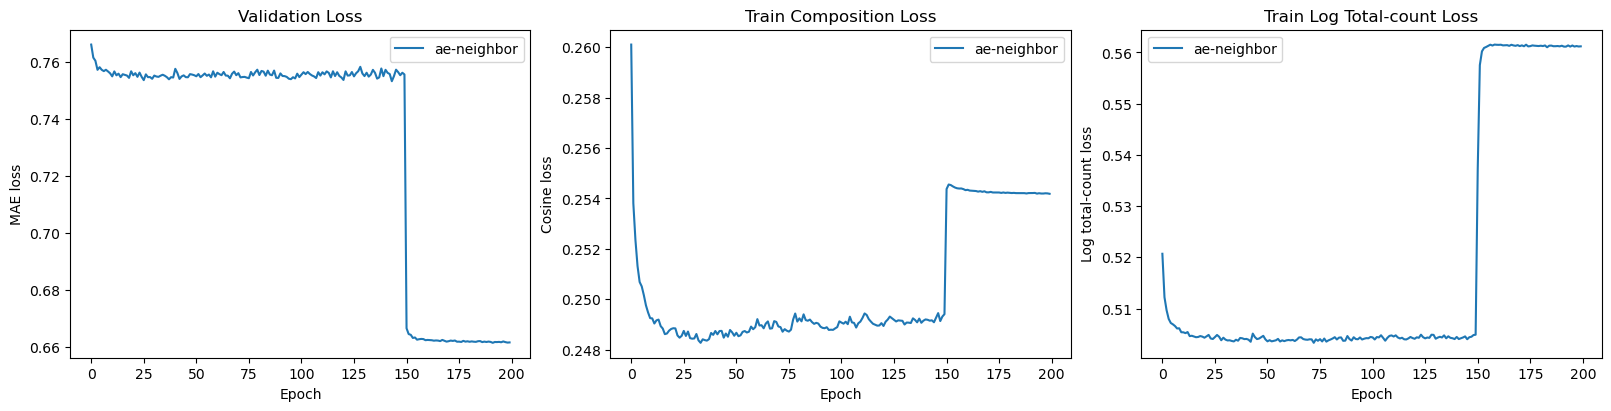

In [13]:
comparison_summary = {
    'AE-neighbor init': {
        'train': ae_coarse_result['train_metrics'],
        'val': ae_coarse_result['val_metrics'],
        'test': ae_coarse_result['test_metrics'],
    },
}
print('Training summary')
print(format_for_display(comparison_summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(ae_coarse_result['history']['val_loss'], label='ae-neighbor')
axes[0].set_title('Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MAE loss')
axes[0].legend()

axes[1].plot(ae_coarse_result['history']['train_composition_loss'], label='ae-neighbor')
axes[1].set_title('Train Composition Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cosine loss')
axes[1].legend()

axes[2].plot(ae_coarse_result['history']['train_total_count_loss'], label='ae-neighbor')
axes[2].set_title('Train Log Total-count Loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Log total-count loss')
axes[2].legend()

export_figure_axes(fig, fallback_prefix='validation_training_losses')
plt.show()


## Splat Layout Comparison

Compare the active splat locations and true-scale ellipse coverage for the random and AE-neighbor models.


In [ ]:

set_seed(layout_seed)
layout_query_idx = torch.randperm(len(cell_features), device=device)[:min(512, len(cell_features))]
layout_queries = cell_features[layout_query_idx]

layout_models = [('AE-neighbor init', ae_coarse_result)]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
axes = np.atleast_2d(axes)
layout_summaries = {}

for row, (label, result) in enumerate(layout_models):
    model = restore_result_model(result)
    with torch.no_grad():
        layout_weights = compute_splat_weights(model, layout_queries)
        layout_mean_usage = layout_weights.mean(dim=0).detach().cpu().numpy()
        layout_peak_usage = layout_weights.max(dim=0)[0].detach().cpu().numpy()
        layout_means = model.means.detach().cpu().numpy()
        layout_scales_xy = torch.exp(model.log_scales).detach().cpu().numpy()
        layout_rotation = model.rotation.detach().cpu().numpy().reshape(-1)

    active_mask = layout_mean_usage > 1e-4
    active_idx = np.flatnonzero(active_mask)
    overlap_usage, overlap_counts = compute_overlap_usage_for_active_splats(
        model,
        cell_features,
        layout_means,
        layout_scales_xy,
        layout_rotation,
        active_idx,
        layout_mean_usage,
        batch_size=512,
    )

    layout_summaries[label] = {
        'active_splats': int(len(active_idx)),
        'total_splats': int(len(layout_mean_usage)),
        'mean_usage_active': float(layout_mean_usage[active_idx].mean()) if len(active_idx) else float('nan'),
        'mean_overlap_usage_active': float(overlap_usage[active_idx].mean()) if len(active_idx) else float('nan'),
        'median_overlap_measurement_count_active': float(np.median(overlap_counts[active_idx])) if len(active_idx) else float('nan'),
        'median_scale_x_active': float(np.median(layout_scales_xy[active_idx, 0])) if len(active_idx) else float('nan'),
        'median_scale_y_active': float(np.median(layout_scales_xy[active_idx, 1])) if len(active_idx) else float('nan'),
        'mean_peak_usage_active': float(layout_peak_usage[active_idx].mean()) if len(active_idx) else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.08, color='black')
    if len(active_idx):
        sc0 = ax0.scatter(
            layout_means[active_idx, 0],
            layout_means[active_idx, 1],
            c=overlap_usage[active_idx],
            s=28.0,
            cmap='viridis',
            alpha=0.9,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active Splat Centers (colored by overlap usage)')

    ax1 = axes[row, 1]
    ax1.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    draw_order = np.argsort(overlap_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    overlap_max = float(overlap_usage[active_idx].max()) if len(active_idx) else 1.0
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        ellipse = Ellipse(
            xy=layout_means[splat_idx],
            width=2.0 * layout_scales_xy[splat_idx, 0],
            height=2.0 * layout_scales_xy[splat_idx, 1],
            angle=float(np.degrees(layout_rotation[splat_idx])),
            facecolor=plt.cm.viridis(min(1.0, max(0.0, overlap_usage[splat_idx] / (overlap_max + 1e-8)))),
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * overlap_usage[splat_idx], 0.18, 0.92)),
        )
        ax1.add_patch(ellipse)
    ax1.set_title(f'{label} | True-Scale Active Splats')

    for ax in (ax0, ax1):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')

    offload_result_model(result)

export_figure_axes(fig, fallback_prefix='true_scale_layout')
plt.show()
print('Splat layout summary')
print(format_for_display(layout_summaries))


## Overlap Diagnostics

Measure mixture overlap and center spacing more directly for the two coarse models.


In [15]:
set_seed(overlap_seed)
overlap_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
overlap_queries = cell_features[overlap_query_idx]

overlap_summary = {}
for label, result in layout_models:
    model = restore_result_model(result)
    with torch.no_grad():
        overlap_weights = compute_splat_weights(model, overlap_queries)
        usage = usage_statistics(overlap_weights)
        means_np = model.means.detach().cpu().numpy()
        pairwise = np.linalg.norm(means_np[:, None, :] - means_np[None, :, :], axis=-1)
        pairwise[pairwise == 0.0] = np.inf
        nearest_center_dist = pairwise.min(axis=1)
        active_mask = overlap_weights.mean(dim=0).detach().cpu().numpy() > 1e-4
        active_nearest = nearest_center_dist[active_mask] if np.any(active_mask) else np.array([], dtype=np.float64)

    overlap_summary[label] = {
        'sampled_queries': int(overlap_queries.shape[0]),
        'active_splat_fraction_gt_1e4': float(usage['active_fraction']),
        'dominant_splat_fraction_gt_5pct': float(usage['dominant_fraction']),
        'avg_splats_per_query_gt_1pct': float(usage['avg_splats_per_query_gt_1pct']),
        'median_nearest_center_distance_all': float(np.median(nearest_center_dist)),
        'mean_nearest_center_distance_all': float(np.mean(nearest_center_dist)),
        'median_nearest_center_distance_active': float(np.median(active_nearest)) if len(active_nearest) else float('nan'),
        'mean_nearest_center_distance_active': float(np.mean(active_nearest)) if len(active_nearest) else float('nan'),
    }
    offload_result_model(result)

print('Coarse overlap summary')
print(format_for_display(overlap_summary))


Coarse overlap summary
{'AE-neighbor init': {'sampled_queries': 2048, 'active_splat_fraction_gt_1e4': 0.56, 'dominant_splat_fraction_gt_5pct': 0.598, 'avg_splats_per_query_gt_1pct': 3.253, 'median_nearest_center_distance_all': 0.013, 'mean_nearest_center_distance_all': 0.015, 'median_nearest_center_distance_active': 0.016, 'mean_nearest_center_distance_active': 0.017}}


## Amplitude Diagnostics

Compare each coarse model's learned splat amplitudes against the local total-count scale of nearby cells.


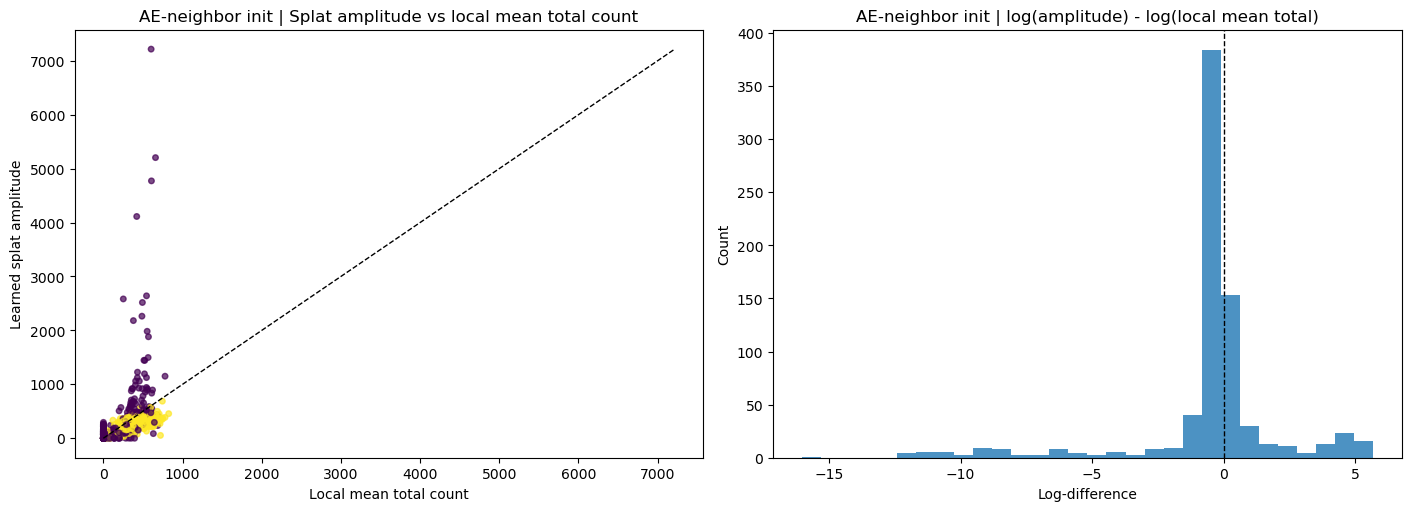

Amplitude summary
{'AE-neighbor init': {'neighbor_k': 16, 'mean_local_total_count': 334.789, 'mean_splat_amplitude': 317.346, 'median_splat_amplitude': 281.111, 'median_abs_log_amp_minus_local_mean': 0.479, 'mean_abs_log_amp_minus_local_mean': 1.45, 'median_abs_log_amp_minus_local_median': 0.435, 'mean_abs_log_amp_minus_local_median': 1.418, 'median_amp_to_local_mean_ratio': 0.744, 'median_amp_to_local_median_ratio': 0.816, 'active_splats': 442, 'median_abs_log_amp_minus_local_mean_active': 0.391, 'median_amp_to_local_mean_ratio_active': 0.682}}


In [16]:
amplitude_diag_neighbor_k = init_neighbor_k
amplitude_summary = {}
fig, axes = plt.subplots(len(layout_models), 2, figsize=(14, 5 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, result) in enumerate(layout_models):
    model = restore_result_model(result)
    with torch.no_grad():
        neighbor_k = min(amplitude_diag_neighbor_k, cell_features.shape[0])
        local_mean_totals, local_median_totals = batched_local_total_statistics(
            model,
            cell_features,
            cell_total_counts,
            neighbor_k=neighbor_k,
        )
        splat_amplitudes = model.splat_amplitudes().detach().squeeze(-1)
        mean_usage = batched_mean_splat_usage(model, cell_features)
        active_mask = mean_usage > 1e-4

        log_amp = splat_amplitudes.clamp_min(1e-8).log()
        log_local_mean = local_mean_totals.clamp_min(1e-8).log()
        log_local_median = local_median_totals.clamp_min(1e-8).log()
        mean_log_diff = log_amp - log_local_mean
        median_log_diff = log_amp - log_local_median

    active_np = active_mask.detach().cpu().numpy()
    splat_amp_np = splat_amplitudes.detach().cpu().numpy()
    local_mean_np = local_mean_totals.detach().cpu().numpy()
    local_median_np = local_median_totals.detach().cpu().numpy()
    mean_log_diff_np = mean_log_diff.detach().cpu().numpy()
    median_log_diff_np = median_log_diff.detach().cpu().numpy()

    amplitude_summary[label] = {
        'neighbor_k': int(neighbor_k),
        'mean_local_total_count': float(local_mean_totals.mean().item()),
        'mean_splat_amplitude': float(splat_amplitudes.mean().item()),
        'median_splat_amplitude': float(splat_amplitudes.median().item()),
        'median_abs_log_amp_minus_local_mean': float(np.median(np.abs(mean_log_diff_np))),
        'mean_abs_log_amp_minus_local_mean': float(np.mean(np.abs(mean_log_diff_np))),
        'median_abs_log_amp_minus_local_median': float(np.median(np.abs(median_log_diff_np))),
        'mean_abs_log_amp_minus_local_median': float(np.mean(np.abs(median_log_diff_np))),
        'median_amp_to_local_mean_ratio': float(np.median(splat_amp_np / np.clip(local_mean_np, 1e-8, None))),
        'median_amp_to_local_median_ratio': float(np.median(splat_amp_np / np.clip(local_median_np, 1e-8, None))),
        'active_splats': int(active_np.sum()),
        'median_abs_log_amp_minus_local_mean_active': float(np.median(np.abs(mean_log_diff_np[active_np]))) if active_np.any() else float('nan'),
        'median_amp_to_local_mean_ratio_active': float(np.median((splat_amp_np / np.clip(local_mean_np, 1e-8, None))[active_np])) if active_np.any() else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.scatter(local_mean_np, splat_amp_np, s=16, alpha=0.7, c=np.where(active_np, 1.0, 0.25), cmap='viridis')
    lo = float(min(local_mean_np.min(), splat_amp_np.min()))
    hi = float(max(local_mean_np.max(), splat_amp_np.max()))
    ax0.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    ax0.set_title(f'{label} | Splat amplitude vs local mean total count')
    ax0.set_xlabel('Local mean total count')
    ax0.set_ylabel('Learned splat amplitude')

    ax1 = axes[row, 1]
    ax1.hist(mean_log_diff_np, bins=30, alpha=0.8, color='tab:blue')
    ax1.axvline(0.0, linestyle='--', color='black', linewidth=1.0)
    ax1.set_title(f'{label} | log(amplitude) - log(local mean total)')
    ax1.set_xlabel('Log-difference')
    ax1.set_ylabel('Count')

    offload_result_model(result)

export_figure_axes(fig, fallback_prefix='amplitude_diagnostics')
plt.show()
print('Amplitude summary')
print(format_for_display(amplitude_summary))


## Total-Count Diagnostics

Check whether the field-level predicted cell total counts are actually worse in the AE-seeded models, or whether the low per-splat amplitudes are just a distributed-representation effect.


Total-count fit summary
{'AE-neighbor init': {'val': {'n': 74174, 'zero_count_cells': 241, 'count_le_1': 268, 'count_le_5': 370, 'count_le_10': 510, 'mae_total_count': 191.425, 'median_abs_total_count_error': 144.221, 'mae_log_total_count': 0.617, 'median_abs_log_total_count_error': 0.474, 'corr_total_count': 0.26, 'corr_log_total_count': 0.674, 'median_pred_to_true_ratio': 0.749, 'mean_pred_to_true_ratio': 11649806.0, 'filtered_ratio_summary': {'total_count>=1': {'n': 73933, 'median_pred_to_true_ratio': 0.747, 'mean_log_pred_minus_log_true': -0.192, 'mae_total_count': 191.932, 'mae_log_total_count': 0.563}, 'total_count>=5': {'n': 73831, 'median_pred_to_true_ratio': 0.746, 'mean_log_pred_minus_log_true': -0.196, 'mae_total_count': 191.99, 'mae_log_total_count': 0.558}, 'total_count>=10': {'n': 73692, 'median_pred_to_true_ratio': 0.746, 'mean_log_pred_minus_log_true': -0.202, 'mae_total_count': 192.0, 'mae_log_total_count': 0.553}, 'total_count>=25': {'n': 73298, 'median_pred_to_true_r

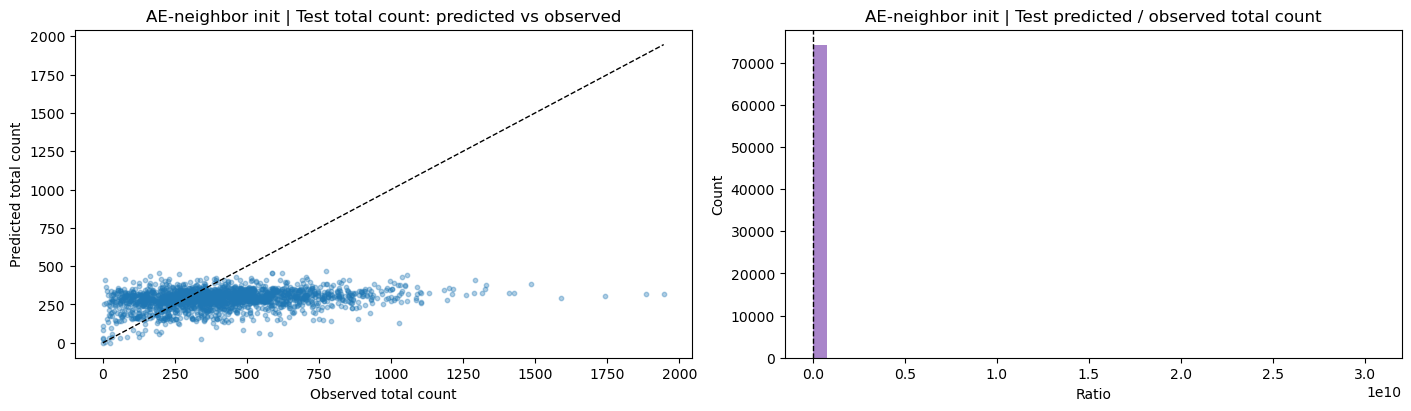

In [17]:
def evaluate_total_count_fit(model, idx: torch.Tensor, batch_size: int = 512):
    was_training = model.training
    model.eval()
    pred_total_chunks = []
    true_total_chunks = []
    with torch.no_grad():
        for start in range(0, len(idx), batch_size):
            batch_idx = idx[start:start + batch_size]
            pred_log_rate = predict_cell_log_rates(
                model,
                cell_features[batch_idx],
                cell_spans[batch_idx],
                batch_size=batch_size,
            )
            pred_total_chunks.append(torch.exp(pred_log_rate).sum(dim=1))
            true_total_chunks.append(cell_targets[batch_idx].sum(dim=1))
    if was_training:
        model.train()
    pred_total = torch.cat(pred_total_chunks, dim=0).detach().cpu().numpy()
    true_total = torch.cat(true_total_chunks, dim=0).detach().cpu().numpy()
    log_pred = np.log(np.clip(pred_total, 1e-8, None))
    log_true = np.log(np.clip(true_total, 1e-8, None))
    ratio = pred_total / np.clip(true_total, 1e-8, None)
    filtered_ratio_summary = {}
    for min_total_count in (1.0, 5.0, 10.0, 25.0):
        mask = true_total >= min_total_count
        key = f'total_count>={int(min_total_count)}'
        filtered_ratio_summary[key] = {
            'n': int(mask.sum()),
            'median_pred_to_true_ratio': float(np.median(ratio[mask])) if mask.any() else float('nan'),
            'mean_log_pred_minus_log_true': float(np.mean(log_pred[mask] - log_true[mask])) if mask.any() else float('nan'),
            'mae_total_count': float(np.mean(np.abs(pred_total[mask] - true_total[mask]))) if mask.any() else float('nan'),
            'mae_log_total_count': float(np.mean(np.abs(log_pred[mask] - log_true[mask]))) if mask.any() else float('nan'),
        }
    return {
        'n': int(len(true_total)),
        'zero_count_cells': int(np.sum(true_total == 0.0)),
        'count_le_1': int(np.sum(true_total <= 1.0)),
        'count_le_5': int(np.sum(true_total <= 5.0)),
        'count_le_10': int(np.sum(true_total <= 10.0)),
        'pred_total': pred_total,
        'true_total': true_total,
        'mae_total_count': float(np.mean(np.abs(pred_total - true_total))),
        'median_abs_total_count_error': float(np.median(np.abs(pred_total - true_total))),
        'mae_log_total_count': float(np.mean(np.abs(log_pred - log_true))),
        'median_abs_log_total_count_error': float(np.median(np.abs(log_pred - log_true))),
        'corr_total_count': float(np.corrcoef(pred_total, true_total)[0, 1]) if len(true_total) > 1 and np.std(pred_total) > 0 and np.std(true_total) > 0 else float('nan'),
        'corr_log_total_count': float(np.corrcoef(log_pred, log_true)[0, 1]) if len(true_total) > 1 and np.std(log_pred) > 0 and np.std(log_true) > 0 else float('nan'),
        'median_pred_to_true_ratio': float(np.median(ratio)),
        'mean_pred_to_true_ratio': float(np.mean(ratio)),
        'filtered_ratio_summary': filtered_ratio_summary,
    }

count_fit_summary = {}
count_fit_store = {}
for label, result in layout_models:
    model = restore_result_model(result)
    val_fit = evaluate_total_count_fit(model, cell_val_idx)
    test_fit = evaluate_total_count_fit(model, cell_test_idx)
    count_fit_store[label] = {'val': val_fit, 'test': test_fit}
    count_fit_summary[label] = {
        'val': {k: v for k, v in val_fit.items() if k not in {'pred_total', 'true_total'}},
        'test': {k: v for k, v in test_fit.items() if k not in {'pred_total', 'true_total'}},
    }
    offload_result_model(result)

print('Total-count fit summary')
print(format_for_display(count_fit_summary))

fig, axes = plt.subplots(len(layout_models), 2, figsize=(14, 4 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, _) in enumerate(layout_models):
    test_fit = count_fit_store[label]['test']
    pred_total = test_fit['pred_total']
    true_total = test_fit['true_total']
    sample_n = min(2048, len(true_total))
    sample_idx = np.linspace(0, len(true_total) - 1, sample_n, dtype=int)
    x_true = true_total[sample_idx]
    y_pred = pred_total[sample_idx]

    ax0 = axes[row, 0]
    ax0.scatter(x_true, y_pred, s=10, alpha=0.35)
    lo = float(min(x_true.min(), y_pred.min()))
    hi = float(max(x_true.max(), y_pred.max()))
    ax0.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    ax0.set_title(f'{label} | Test total count: predicted vs observed')
    ax0.set_xlabel('Observed total count')
    ax0.set_ylabel('Predicted total count')

    ax1 = axes[row, 1]
    ratio = pred_total / np.clip(true_total, 1e-8, None)
    ax1.hist(ratio, bins=40, alpha=0.8, color='tab:purple')
    ax1.axvline(1.0, linestyle='--', color='black', linewidth=1.0)
    ax1.set_title(f'{label} | Test predicted / observed total count')
    ax1.set_xlabel('Ratio')
    ax1.set_ylabel('Count')

export_figure_axes(fig, fallback_prefix='total_count_fit')
plt.show()


## Program Drift Diagnostics

Compare decoded splat programs before and after coarse training to see whether the AE-initialized biological programs stay coherent after decoder fine-tuning.


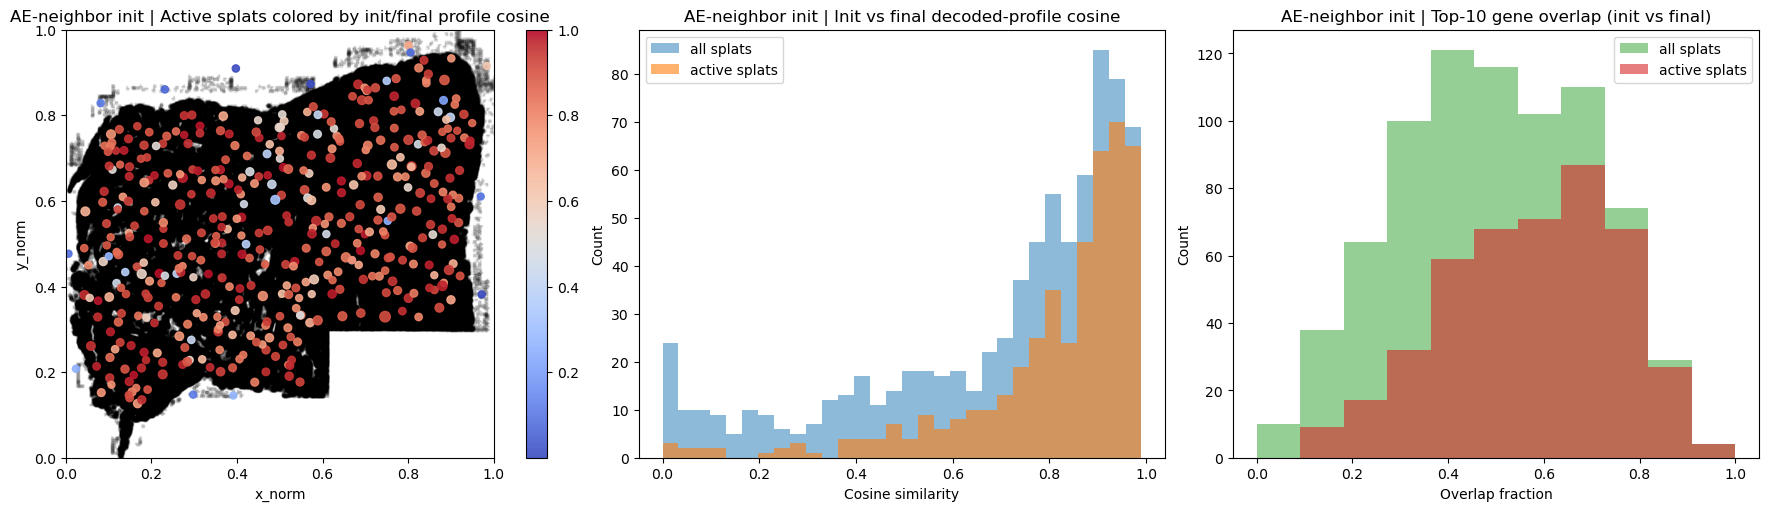

Program drift summary
{'AE-neighbor init': {'active_splats': 442, 'mean_profile_cosine_all': 0.698, 'median_profile_cosine_all': 0.795, 'mean_profile_cosine_active': 0.807, 'median_profile_cosine_active': 0.878, 'mean_top10_overlap_all': 0.495, 'median_top10_overlap_all': 0.5, 'mean_top10_overlap_active': 0.583, 'median_top10_overlap_active': 0.6, 'program_geometry_corr_active': 0.536}}


In [18]:
with torch.no_grad():
    init_gene_logits, _ = encoder_initialized_splat_model.decoder(encoder_initialized_splat_model.latents)
    init_profiles = torch.softmax(init_gene_logits, dim=1)

program_drift_models = [('AE-neighbor init', ae_coarse_result)]

top_gene_k = min(10, num_genes)
program_drift_summary = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, result) in enumerate(program_drift_models):
    model = restore_result_model(result)
    with torch.no_grad():
        final_gene_logits, _ = model.decoder(model.latents)
        final_profiles = torch.softmax(final_gene_logits, dim=1)
        init_norm = init_profiles / init_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        final_norm = final_profiles / final_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profile_cosine = (init_norm * final_norm).sum(dim=1)
        mean_usage = batched_mean_splat_usage(model, cell_features)
        active_mask = mean_usage > 1e-4

        init_top = torch.topk(init_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        final_top = torch.topk(final_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_overlap = np.array([
            len(set(init_top[i].tolist()) & set(final_top[i].tolist())) / float(top_gene_k)
            for i in range(init_top.shape[0])
        ], dtype=np.float64)

        active_idx = torch.nonzero(active_mask, as_tuple=False).squeeze(1)
        if active_idx.numel() >= 2:
            init_active = init_norm[active_idx]
            final_active = final_norm[active_idx]
            init_pairwise = (init_active @ init_active.T).detach().cpu().numpy()
            final_pairwise = (final_active @ final_active.T).detach().cpu().numpy()
            tri = np.triu_indices(init_pairwise.shape[0], k=1)
            if len(tri[0]) > 1 and np.std(init_pairwise[tri]) > 0 and np.std(final_pairwise[tri]) > 0:
                program_geometry_corr = float(np.corrcoef(init_pairwise[tri], final_pairwise[tri])[0, 1])
            else:
                program_geometry_corr = float('nan')
        else:
            program_geometry_corr = float('nan')

    profile_cosine_np = profile_cosine.detach().cpu().numpy()
    mean_usage_np = mean_usage.detach().cpu().numpy()
    active_np = active_mask.detach().cpu().numpy()
    means_np = model.means.detach().cpu().numpy()

    program_drift_summary[label] = {
        'active_splats': int(active_np.sum()),
        'mean_profile_cosine_all': float(np.mean(profile_cosine_np)),
        'median_profile_cosine_all': float(np.median(profile_cosine_np)),
        'mean_profile_cosine_active': float(np.mean(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'median_profile_cosine_active': float(np.median(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'mean_top10_overlap_all': float(np.mean(top_overlap)),
        'median_top10_overlap_all': float(np.median(top_overlap)),
        'mean_top10_overlap_active': float(np.mean(top_overlap[active_np])) if active_np.any() else float('nan'),
        'median_top10_overlap_active': float(np.median(top_overlap[active_np])) if active_np.any() else float('nan'),
        'program_geometry_corr_active': program_geometry_corr,
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.18)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.06, color='black')
    if active_np.any():
        sc0 = ax0.scatter(
            means_np[active_np, 0],
            means_np[active_np, 1],
            c=profile_cosine_np[active_np],
            s=25.0 + 2500.0 * np.clip(mean_usage_np[active_np], 0.0, None),
            cmap='coolwarm',
            alpha=0.9,
            vmin=max(0.0, float(np.nanmin(profile_cosine_np[active_np]))),
            vmax=1.0,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active splats colored by init/final profile cosine')
    ax0.set_xlim(0, 1)
    ax0.set_ylim(0, 1)
    ax0.set_aspect('equal')
    ax0.set_xlabel('x_norm')
    ax0.set_ylabel('y_norm')

    ax1 = axes[row, 1]
    ax1.hist(profile_cosine_np, bins=30, alpha=0.5, label='all splats', color='tab:blue')
    if active_np.any():
        ax1.hist(profile_cosine_np[active_np], bins=30, alpha=0.6, label='active splats', color='tab:orange')
    ax1.set_title(f'{label} | Init vs final decoded-profile cosine')
    ax1.set_xlabel('Cosine similarity')
    ax1.set_ylabel('Count')
    ax1.legend()

    ax2 = axes[row, 2]
    ax2.hist(top_overlap, bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.5, label='all splats', color='tab:green')
    if active_np.any():
        ax2.hist(top_overlap[active_np], bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.6, label='active splats', color='tab:red')
    ax2.set_title(f'{label} | Top-{top_gene_k} gene overlap (init vs final)')
    ax2.set_xlabel('Overlap fraction')
    ax2.set_ylabel('Count')
    ax2.legend()

    offload_result_model(result)

export_figure_axes(fig, fallback_prefix='program_drift')
plt.show()
print('Program drift summary')
print(format_for_display(program_drift_summary))


## Cellular Program Analysis

Cluster the active decoded splat programs from the AE-neighbor model and visualize their spatial arrangement, amplitude, and true-scale support.


In [ ]:

program_usage_query_idx = torch.randperm(len(cell_features), device=device)[:min(512, len(cell_features))]
program_queries = cell_features[program_usage_query_idx]
program_model = restore_result_model(ae_coarse_result)
program_label = 'AE-neighbor'
program_n_clusters = min(8, splat_cfg.num_splats)

with torch.no_grad():
    program_weights = compute_splat_weights(program_model, program_queries)
    program_mean_usage = program_weights.mean(dim=0).detach().cpu().numpy()
    program_peak_usage = program_weights.max(dim=0)[0].detach().cpu().numpy()

    gene_logits, _ = program_model.decoder(program_model.latents)
    program_composition = torch.softmax(gene_logits, dim=-1).detach().cpu().numpy()
    program_total_intensity = program_model.splat_amplitudes().detach().cpu().numpy().reshape(-1)
    program_rates = program_total_intensity[:, None] * program_composition

    program_means = program_model.means.detach().cpu().numpy()
    program_scales_xy = torch.exp(program_model.log_scales).detach().cpu().numpy()
    program_scales = program_scales_xy.mean(axis=1)
    program_rotation = program_model.rotation.detach().cpu().numpy().reshape(-1)
    program_opacity = torch.sigmoid(program_model.opacity_logits).squeeze(-1).detach().cpu().numpy()

active_mask = program_mean_usage > 1e-4
active_idx = np.flatnonzero(active_mask)
program_overlap_usage, program_overlap_counts = compute_overlap_usage_for_active_splats(
    program_model,
    cell_features,
    program_means,
    program_scales_xy,
    program_rotation,
    active_idx,
    program_mean_usage,
    batch_size=512,
)

print(f'{program_label} active splats for program clustering: {len(active_idx)} / {len(program_mean_usage)}')

program_amplitude_summary = {
    'all_splats': {
        'mean': float(program_total_intensity.mean()),
        'std': float(program_total_intensity.std()),
        'min': float(program_total_intensity.min()),
        'median': float(np.median(program_total_intensity)),
        'q90': float(np.quantile(program_total_intensity, 0.90)),
        'q99': float(np.quantile(program_total_intensity, 0.99)),
        'max': float(program_total_intensity.max()),
    },
    'active_splats': {
        'mean': float(program_total_intensity[active_idx].mean()) if len(active_idx) else float('nan'),
        'std': float(program_total_intensity[active_idx].std()) if len(active_idx) else float('nan'),
        'min': float(program_total_intensity[active_idx].min()) if len(active_idx) else float('nan'),
        'median': float(np.median(program_total_intensity[active_idx])) if len(active_idx) else float('nan'),
        'q90': float(np.quantile(program_total_intensity[active_idx], 0.90)) if len(active_idx) else float('nan'),
        'q99': float(np.quantile(program_total_intensity[active_idx], 0.99)) if len(active_idx) else float('nan'),
        'max': float(program_total_intensity[active_idx].max()) if len(active_idx) else float('nan'),
    },
    'corr_mean_usage_vs_total_intensity': float(np.corrcoef(program_mean_usage, program_total_intensity)[0, 1]) if len(program_mean_usage) > 1 else float('nan'),
    'corr_peak_usage_vs_total_intensity': float(np.corrcoef(program_peak_usage, program_total_intensity)[0, 1]) if len(program_peak_usage) > 1 else float('nan'),
}
print('Per-Splat Amplitudes')
print(format_for_display(program_amplitude_summary))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].hist(program_total_intensity, bins=50, color='steelblue', alpha=0.8)
axes[0].set_title('Per-Splat Amplitude Distribution')
axes[0].set_xlabel('Amplitude')
axes[0].set_ylabel('Splats')

axes[1].scatter(program_mean_usage, program_total_intensity, s=18, alpha=0.5)
axes[1].set_title('Mean Usage vs Amplitude')
axes[1].set_xlabel('Mean usage')
axes[1].set_ylabel('Amplitude')

axes[2].scatter(program_peak_usage, program_total_intensity, s=18, alpha=0.5)
axes[2].set_title('Peak Usage vs Amplitude')
axes[2].set_xlabel('Peak usage')
axes[2].set_ylabel('Amplitude')
export_figure_axes(fig, fallback_prefix='program_amplitudes')
plt.show()

if len(active_idx) < 3:
    print('Not enough active splats to cluster decoded programs.')
else:
    from sklearn.cluster import KMeans
    from sklearn.decomposition import PCA

    active_compositions = program_composition[active_idx]
    active_log_rates = np.log1p(program_rates[active_idx])
    active_intensity = program_total_intensity[active_idx]
    n_clusters = min(program_n_clusters, len(active_idx))
    if n_clusters < 2:
        n_clusters = 2

    print(format_for_display({'chosen_k': int(n_clusters)}))
    program_clusters = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit_predict(active_compositions)

    try:
        import umap
        reducer = umap.UMAP(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'UMAP'
    except ImportError:
        reducer = PCA(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'PCA fallback (umap-learn not installed)'

    cluster_top = {}
    for cluster_id in range(n_clusters):
        cluster_mean = active_compositions[program_clusters == cluster_id].mean(axis=0)
        top_idx = np.argsort(cluster_mean)[-5:][::-1]
        cluster_top[cluster_id] = [gene_list[i] for i in top_idx]

    tab10 = plt.cm.tab10(np.arange(10))
    color_order = np.array([0, 1, 2, 3, 4, 5, 6, 9, 8])
    cluster_colors = tab10[color_order[:n_clusters]]
    point_colors = cluster_colors[program_clusters]
    scatter_alpha = np.clip(0.25 + 6.0 * program_overlap_usage[active_idx], 0.25, 0.95)

    fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
    axes[0, 0].imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25)
    axes[0, 0].scatter(
        program_means[active_idx, 0],
        program_means[active_idx, 1],
        color=point_colors,
        s=32.0,
        alpha=scatter_alpha,
    )
    axes[0, 0].set_title(f'{program_label} | Active Splats Colored by Composition Cluster')
    axes[0, 0].set_xlim(0, 1)
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_aspect('equal')
    axes[0, 0].set_xlabel('x_norm')
    axes[0, 0].set_ylabel('y_norm')

    axes[0, 1].scatter(
        embedding[:, 0],
        embedding[:, 1],
        color=point_colors,
        s=32.0,
        alpha=scatter_alpha,
    )
    axes[0, 1].set_title(f'Active Splat Compositions in {embedding_label} Space')
    axes[0, 1].set_xlabel(f'{embedding_label} 1')
    axes[0, 1].set_ylabel(f'{embedding_label} 2')

    order = np.argsort(program_clusters)
    sample_cap = min(300, len(active_idx))
    show_order = order[:sample_cap]
    show_clusters = program_clusters[show_order]
    variable_gene_k = min(100, active_log_rates.shape[1])
    variable_gene_idx = np.argsort(active_log_rates.var(axis=0))[::-1][:variable_gene_k]
    show_programs = active_log_rates[show_order][:, variable_gene_idx]
    show_programs_row_norm = show_programs / np.clip(show_programs.max(axis=1, keepdims=True), 1e-8, None)
    im = axes[1, 0].imshow(show_programs_row_norm, aspect='auto', cmap='magma', vmin=0.0, vmax=1.0)
    axes[1, 0].set_title('Decoded Active Splat Programs (row-normalized top-variable genes)')
    axes[1, 0].set_xlabel('Top variable gene index')
    axes[1, 0].set_ylabel('Active splats (cluster-sorted subset)')
    cluster_breaks = np.where(np.diff(show_clusters) != 0)[0]
    for boundary in cluster_breaks:
        axes[1, 0].axhline(boundary + 0.5, color='white', linewidth=0.7, alpha=0.7)
    fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

    intensity_means = [active_intensity[program_clusters == cluster_id].mean() for cluster_id in range(n_clusters)]
    intensity_stds = [active_intensity[program_clusters == cluster_id].std() for cluster_id in range(n_clusters)]
    axes[1, 1].bar(np.arange(n_clusters), intensity_means, yerr=intensity_stds, color=cluster_colors, alpha=0.8)
    axes[1, 1].set_title('Amplitude by Composition Cluster')
    axes[1, 1].set_xlabel('Composition cluster')
    axes[1, 1].set_ylabel('Amplitude')
    axes[1, 1].set_xticks(np.arange(n_clusters))
    axes[1, 1].set_xticklabels([f'C{cluster_id}' for cluster_id in range(n_clusters)])
    export_figure_axes(fig, fallback_prefix='composition_clusters')
    plt.show()

    draw_order = np.argsort(program_overlap_usage[active_idx])
    fig, ax = plt.subplots(1, 1, figsize=(9, 9), constrained_layout=True)
    ax.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    for local_idx in draw_order:
        splat_idx = active_idx[local_idx]
        cluster_id = int(program_clusters[local_idx])
        ellipse = Ellipse(
            xy=program_means[splat_idx],
            width=2.0 * program_scales_xy[splat_idx, 0],
            height=2.0 * program_scales_xy[splat_idx, 1],
            angle=float(np.degrees(program_rotation[splat_idx])),
            facecolor=cluster_colors[cluster_id],
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * program_overlap_usage[splat_idx], 0.18, 0.92)),
        )
        ax.add_patch(ellipse)
    ax.set_title(f'{program_label} | True-Scale Splats Colored by Composition Cluster')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')
    export_figure_axes(fig, fallback_prefix='true_scale_composition_clusters')
    plt.show()

    print('Shared Program Clusters (composition-based)')
    cluster_program_summary = {}
    for cluster_id in range(n_clusters):
        cluster_mask = program_clusters == cluster_id
        cluster_program_summary[f'cluster_{cluster_id}'] = {
            'n_splats': int(cluster_mask.sum()),
            'mean_usage': float(program_mean_usage[active_idx][cluster_mask].mean()),
            'mean_overlap_usage': float(program_overlap_usage[active_idx][cluster_mask].mean()),
            'mean_opacity': float(program_opacity[active_idx][cluster_mask].mean()),
            'mean_amplitude': float(active_intensity[cluster_mask].mean()),
            'top_genes_by_composition': cluster_top[cluster_id],
        }
    print(format_for_display(cluster_program_summary))

offload_result_model(ae_coarse_result)


## Baseline Comparison Analysis

Compare the AE-neighbor splat model against the trained baselines using the same spatial and per-cell diagnostics used in the modular amplitude notebooks.


In [ ]:
comparison_gene_name = comparison_gene_of_interest if comparison_gene_of_interest in gene_to_id else ('EPCAM' if 'EPCAM' in gene_to_id else gene_list[0])
comparison_gene_idx = gene_to_id[comparison_gene_name]

comparison_mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy() > 0.05
comparison_distance_map = distance_transform_edt(comparison_mask_np).astype(np.float32) / data_cfg.mask_grid_size

def predict_counts_cell_model(model, features, spans, batch_size=512):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(predict_cell_log_rates(model, features[start:start + batch_size], spans[start:start + batch_size], batch_size=batch_size)))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def predict_counts_direct_model(model, features, batch_size=256):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(model(features[start:start + batch_size])))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def per_cell_cosine_similarity(pred_counts, true_counts):
    pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    true_norm = true_counts / true_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    return (pred_norm * true_norm).sum(dim=1).detach().cpu().numpy()


def summarize_count_conditioned_error(total_counts, mae_values):
    q_edges = np.quantile(total_counts, [0.0, 0.25, 0.5, 0.75, 1.0])
    q_edges[0] = np.floor(q_edges[0])
    q_edges[-1] = np.ceil(q_edges[-1])
    labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
    out = {}
    for i, label in enumerate(labels):
        lo = q_edges[i]
        hi = q_edges[i + 1]
        if i == len(labels) - 1:
            mask = (total_counts >= lo) & (total_counts <= hi)
        else:
            mask = (total_counts >= lo) & (total_counts < hi)
        out[label] = {
            'count_range': [float(lo), float(hi)],
            'n': int(mask.sum()),
            'mean_mae': float(mae_values[mask].mean()) if mask.any() else float('nan'),
            'median_mae': float(np.median(mae_values[mask])) if mask.any() else float('nan'),
        }
    corr = np.corrcoef(total_counts, mae_values)[0, 1] if len(total_counts) > 1 else float('nan')
    out['corr_total_count_vs_mae'] = float(corr)
    return out


def summarize_error_distribution(values):
    return {
        'mean': float(np.mean(values)),
        'std': float(np.std(values)),
        'median': float(np.median(values)),
        'q90': float(np.quantile(values, 0.90)),
        'q95': float(np.quantile(values, 0.95)),
        'q99': float(np.quantile(values, 0.99)),
    }

def ecdf_xy(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)
    x = np.sort(values)
    y = np.arange(1, len(x) + 1, dtype=np.float64) / float(len(x))
    return x, y

line_style_map = {
    'AE-neighbor splat': {'marker': 'o', 'linestyle': '-', 'linewidth': 2.8, 'markersize': 8, 'zorder': 5},
    'MLP-MAE': {'marker': 's', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'MLP (Bio Objective)': {'marker': 's', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP-MAE': {'marker': '^', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP (Bio Objective)': {'marker': '^', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'KNN': {'marker': 'D', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Budget-matched KNN': {'marker': 'D', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
}

cell_test_features = cell_features[cell_test_idx]
cell_test_spans = cell_spans[cell_test_idx]
cell_test_targets_local = cell_targets[cell_test_idx]
cell_test_points = cell_test_features.detach().cpu().numpy()
cell_edge_distance = sample_numpy_grid(cell_test_points, comparison_distance_map)
cell_total_counts_test = cell_test_targets_local.sum(dim=1).detach().cpu().numpy()
cell_true_gene = cell_test_targets_local[:, comparison_gene_idx].detach().cpu().numpy()

ae_neighbor_splat_model = restore_result_model(ae_coarse_result)

comparison_models = [
    ('AE-neighbor splat', ae_neighbor_splat_model, 'cell_model'),
    ('MLP-MAE', cell_mlp_mae.to(device), 'direct_model'),
    ('MLP (Bio Objective)', cell_mlp.to(device), 'direct_model'),
    ('Fourier MLP-MAE', cell_fourier_mlp_mae.to(device), 'direct_model'),
    ('Fourier MLP (Bio Objective)', cell_fourier_mlp.to(device), 'direct_model'),
    ('KNN', cell_knn.to(device), 'direct_model'),
    ('Budget-matched KNN', cell_budget_knn.to(device), 'direct_model'),
]

print(f'Comparison Gene: {comparison_gene_name}')
print('Edge vs Interior Error')
plot_specs = []
for label, model, model_kind in comparison_models:
    if model_kind == 'cell_model':
        pred_counts = predict_counts_cell_model(model, cell_test_features, cell_test_spans)
    else:
        pred_counts = predict_counts_direct_model(model, cell_test_features, batch_size=256)
    mae_values = (pred_counts - cell_test_targets_local).abs().mean(dim=1).detach().cpu().numpy()
    gene_values = pred_counts[:, comparison_gene_idx].detach().cpu().numpy()
    signed_values = gene_values - cell_true_gene
    cosine_values = per_cell_cosine_similarity(pred_counts, cell_test_targets_local)
    print(label, format_for_display(summarize_error_slices(mae_values, cell_edge_distance)))
    print(label, format_for_display(summarize_activity_slices(signed_values, cell_true_gene)))
    plot_specs.append((label, mae_values, signed_values, cosine_values))

print('MAE By Total Measurement Counts')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_count_conditioned_error(cell_total_counts_test, mae_values)))

print('Per-measurement MAE Distribution')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_error_distribution(mae_values)))

print('Per-cell Cosine Similarity')
for label, _, _, cosine_values in plot_specs:
    print(label, format_for_display(summarize_error_distribution(cosine_values)))

all_mae_values = np.concatenate([mae_values for _, mae_values, _, _ in plot_specs])
all_signed_values = np.concatenate([signed_values for _, _, signed_values, _ in plot_specs])
mae_vmax = np.quantile(all_mae_values, 0.98) if len(all_mae_values) else 1.0
signed_vmax = np.quantile(np.abs(all_signed_values), 0.98) if np.any(np.abs(all_signed_values) > 0) else 1.0

fig, axes = plt.subplots(len(plot_specs), 2, figsize=(12, 5 * len(plot_specs)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, mae_values, signed_values, _) in enumerate(plot_specs):
    for col, (values, suffix, cmap) in enumerate([
        (mae_values, 'MAE', 'magma'),
        (signed_values, f'Signed Error ({comparison_gene_name})', 'coolwarm'),
    ]):
        ax = axes[row, col]
        ax.imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
        if cmap == 'coolwarm':
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=-signed_vmax, vmax=signed_vmax)
        else:
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=0.0, vmax=mae_vmax)
        ax.set_title(f'{label} {suffix}')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='comparison_panels')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    x, y = ecdf_xy(mae_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-measurement MAE ECDF')
axes[0].set_xlabel('Per-measurement MAE')
axes[0].set_ylabel('Fraction of measurements <= x')
axes[0].legend()

refined_label = 'AE-neighbor splat'
refined_mae = next(mae_values for label, mae_values, _, _ in plot_specs if label == refined_label)
worst_thresh = np.quantile(refined_mae, 0.95) if len(refined_mae) else 0.0
worst_mask = refined_mae >= worst_thresh
axes[1].imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
sc = axes[1].scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=refined_mae, s=np.where(worst_mask, 24, 8), cmap='magma', alpha=np.where(worst_mask, 0.95, 0.18), vmin=0.0, vmax=mae_vmax)
axes[1].set_title(f'Worst 5% Cells By MAE ({refined_label})')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect('equal')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')
fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='mae_ecdf')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    axes[0].scatter(cell_total_counts_test, mae_values, s=6, alpha=0.15, label=label)
axes[0].set_title('Per-measurement MAE vs Total Counts')
axes[0].set_xlabel('Total measurement counts')
axes[0].set_ylabel('Per-measurement MAE')
axes[0].legend(markerscale=2)

count_edges = np.quantile(cell_total_counts_test, [0.0, 0.25, 0.5, 0.75, 1.0])
count_labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
for label, mae_values, _, _ in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(mae_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('MAE by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-cell MAE')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='mae_counts')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, _, _, cosine_values in plot_specs:
    x, y = ecdf_xy(cosine_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-cell Cosine Similarity ECDF')
axes[0].set_xlabel('Per-measurement cosine similarity')
axes[0].set_ylabel('Fraction of measurements <= x')
axes[0].legend()

for label, _, _, cosine_values in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(cosine_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('Cosine Similarity by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-cell cosine similarity')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='cosine_counts')
plt.show()

for _, model, model_kind in comparison_models:
    if model_kind == 'direct_model':
        model.cpu()
offload_result_model(ae_coarse_result)
maybe_clear_cuda()


## Next

Use this notebook as the clean coarse-analysis template for the MERFISH uterine-cancer dataset. Because the tissue is much larger, favor smaller first-pass sweeps, save intermediate results, and clear GPU memory between heavy sections when needed.
